Mount Google Drive

In [2]:
# CELL 1 — Mount Google Drive

try:
    from google.colab import drive
    drive.mount("/content/drive")
    print("Google Drive mounted successfully!")
except Exception as e:
    print("Google Drive mount skipped (running locally):", e)


Mounted at /content/drive
Google Drive mounted successfully!


In [3]:
# CELL 2 — Project Paths & Checkpoint Check

import os
from pathlib import Path

# Main project directory - support both Colab and local execution
candidate_dirs = [
    Path("/content/drive/MyDrive/project-1/mango-disease-prediction"),
    Path(__file__).resolve().parents[1] if "__file__" in globals() else None,
    Path("mango-disease-prediction").resolve(),
    Path(".").resolve(),
    Path("..").resolve(),
]
PROJECT_DIR = None
for candidate in candidate_dirs:
    if candidate and (candidate / "models/full_multimodal/best_model.pth").is_file():
        PROJECT_DIR = candidate
        break

if PROJECT_DIR is None:
    PROJECT_DIR = Path("/content/drive/MyDrive/project-1/mango-disease-prediction")

# Important directories
MODELS_DIR = PROJECT_DIR / "models"
DATA_DIR = PROJECT_DIR / "data"
NOTEBOOK_DIR = PROJECT_DIR

# Best trained multimodal model
CHECKPOINT_PATH = (
    MODELS_DIR
    / "full_multimodal"
    / "best_model.pth"
)

print("Project directory:")
print(PROJECT_DIR)

print("\nCheckpoint:")
print(CHECKPOINT_PATH)

# Verify project directory
if PROJECT_DIR.exists():
    print("\n✅ Project directory exists")
else:
    raise FileNotFoundError(
        f"❌ Project directory not found:\n{PROJECT_DIR}"
    )

# Verify checkpoint
if CHECKPOINT_PATH.exists():
    print("✅ best_model.pth found")
    size_mb = CHECKPOINT_PATH.stat().st_size / (1024 * 1024)
    print(f"Checkpoint size: {size_mb:.2f} MB")
else:
    raise FileNotFoundError(
        f"❌ Checkpoint not found:\n{CHECKPOINT_PATH}"
    )

# Show important folders
print("\nAvailable project folders:")
for item in sorted(PROJECT_DIR.iterdir()):
    if item.is_dir():
        print("📁", item.name)


Project directory:
/content/drive/MyDrive/project-1/mango-disease-prediction

Checkpoint:
/content/drive/MyDrive/project-1/mango-disease-prediction/models/full_multimodal/best_model.pth

✅ Project directory exists
✅ best_model.pth found
Checkpoint size: 485.64 MB

Available project folders:
📁 data
📁 models
📁 notebooks
📁 results
📁 src


In [4]:

# CELL 3 — Inspect Project Structure


from pathlib import Path

print("=" * 70)
print("PROJECT STRUCTURE")
print("=" * 70)

# Show files and folders up to 3 levels deep
max_depth = 3

for path in sorted(PROJECT_DIR.rglob("*")):

    try:
        relative = path.relative_to(PROJECT_DIR)
        depth = len(relative.parts)

        if depth <= max_depth:
            if path.is_dir():
                print("📁", relative)
            else:
                size_mb = path.stat().st_size / (1024 * 1024)

                # Don't print huge files with unnecessary precision
                print(f"📄 {relative} ({size_mb:.2f} MB)")

    except Exception:
        pass


print("\n" + "=" * 70)
print("CHECKPOINT")
print("=" * 70)

print("Exists :", CHECKPOINT_PATH.exists())
print("Path   :", CHECKPOINT_PATH)

if CHECKPOINT_PATH.exists():
    print(
        "Size   :",
        f"{CHECKPOINT_PATH.stat().st_size / (1024 * 1024):.2f} MB"
    )

PROJECT STRUCTURE
📄 .gitignore (0.00 MB)
📄 README.md (0.00 MB)
📄 confusion_matrix_multimodal.png (0.01 MB)
📁 data
📁 data/processed
📄 data/processed/image_metadata.csv (0.50 MB)
📄 data/processed/paired_metadata.csv (0.84 MB)
📄 data/processed/test.csv (0.13 MB)
📄 data/processed/train.csv (0.59 MB)
📄 data/processed/validation.csv (0.13 MB)
📁 data/raw
📁 data/raw/environmental
📁 data/raw/mango
📁 models
📁 models/full_multimodal
📄 models/full_multimodal/best_model.pth (485.64 MB)
📄 models/vit_image_only.pth (327.38 MB)
📁 notebooks
📄 notebooks/01_data_preparation.ipynb (2.45 MB)
📄 notebooks/02_split_normalization.ipynb (0.11 MB)
📄 notebooks/03_edaipynb (0.96 MB)
📄 notebooks/04_baseline_models.ipynb (0.05 MB)
📄 notebooks/04_xai_and_vlm.ipynb (0.08 MB)
📄 notebooks/05_final_model.ipynb (1.36 MB)
📄 requirements.txt (0.00 MB)
📁 results
📄 shap_environmental_importance.png (0.01 MB)
📁 src
📄 src/__init__.py (0.00 MB)
📁 src/__pycache__
📄 src/__pycache__/__init__.cpython-313.pyc (0.00 MB)
📁 src/data
📄 s

Find and inspect datasets safely

In [5]:
# ============================================
# CELL 4 — Find Dataset & Metadata Files
# ============================================

import pandas as pd
from pathlib import Path

print("=" * 70)
print("CSV / METADATA FILES")
print("=" * 70)

csv_files = sorted(PROJECT_DIR.rglob("*.csv"))

if len(csv_files) == 0:
    print("⚠️ No CSV files found.")
else:
    for i, file in enumerate(csv_files, 1):
        try:
            size_mb = file.stat().st_size / (1024 * 1024)

            print(f"\n[{i}] {file.relative_to(PROJECT_DIR)}")
            print(f"    Size: {size_mb:.2f} MB")

            # Read only a few rows so we don't load huge files
            sample = pd.read_csv(file, nrows=3)

            print(f"    Rows sampled: {len(sample)}")
            print(f"    Columns: {list(sample.columns)}")

            if len(sample) > 0:
                print("    Sample:")
                print(sample.head(2).to_string(index=False))

        except Exception as e:
            print(f"    ⚠️ Could not inspect: {e}")


print("\n" + "=" * 70)
print("IMAGE FILE SUMMARY")
print("=" * 70)

image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

image_count = 0
folder_counts = {}

for file in PROJECT_DIR.rglob("*"):
    if file.is_file() and file.suffix.lower() in image_extensions:
        image_count += 1

        try:
            parent = file.parent.relative_to(PROJECT_DIR)
            parent_name = str(parent)

            folder_counts[parent_name] = (
                folder_counts.get(parent_name, 0) + 1
            )
        except Exception:
            pass

print(f"Total image files found: {image_count:,}")

if folder_counts:
    print("\nImage-containing folders:")

    for folder, count in sorted(
        folder_counts.items(),
        key=lambda x: x[1],
        reverse=True
    )[:30]:
        print(f"  📁 {folder}: {count:,} images")


print("\n" + "=" * 70)
print("OTHER METADATA FILES")
print("=" * 70)

for extension in ["*.json", "*.parquet", "*.xlsx"]:
    files = sorted(PROJECT_DIR.rglob(extension))

    if files:
        print(f"\n{extension}:")
        for file in files[:30]:
            size_mb = file.stat().st_size / (1024 * 1024)
            print(
                f"  📄 {file.relative_to(PROJECT_DIR)} "
                f"({size_mb:.2f} MB)"
            )

CSV / METADATA FILES

[1] data/processed/image_metadata.csv
    Size: 0.50 MB
    Rows sampled: 3
    Columns: ['image_path', 'class_name', 'label']
    Sample:
                                                                                                                            image_path  class_name  label
/content/drive/MyDrive/project-1/mango-disease-prediction/data/raw/mango/Anthracnose/20211011_171151 - Copy - Copy - Copy (Custom).jpg Anthracnose      0
                 /content/drive/MyDrive/project-1/mango-disease-prediction/data/raw/mango/Anthracnose/IMG_20211011_153216 (Custom).jpg Anthracnose      0

[2] data/processed/paired_metadata.csv
    Size: 0.84 MB
    Rows sampled: 3
    Columns: ['image_path', 'class_name', 'label', 'sample_index', 'sample_id', 'date', 'time', 'temperature_c', 'humidity_pct', 'rainfall_mm', 'soil_moisture_pct', 'soil_ph', 'season', 'data_status']
    Sample:
                                                                                      

Identify the correct metadata files

In [6]:
# ============================================
# CELL 5 — Identify Metadata & Environmental Data
# ============================================

import pandas as pd
from pathlib import Path

print("=" * 70)
print("DATASET FILE ANALYSIS")
print("=" * 70)

csv_files = sorted(PROJECT_DIR.rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError("❌ No CSV files found in the project.")

# ------------------------------------------------
# Helper function
# ------------------------------------------------

def inspect_csv(file_path):
    """
    Safely inspect only a small portion of a CSV.
    We avoid loading huge datasets into RAM.
    """

    try:
        # Read only first 100 rows
        df = pd.read_csv(file_path, nrows=100)

        columns = [str(c).lower().strip() for c in df.columns]

        image_keywords = [
            "image",
            "img",
            "filepath",
            "file_path",
            "path",
            "filename",
            "file_name"
        ]

        label_keywords = [
            "label",
            "class",
            "disease",
            "target",
            "category"
        ]

        environmental_keywords = [
            "temperature",
            "temp",
            "humidity",
            "rainfall",
            "rain",
            "soil",
            "moisture",
            "ph",
            "season",
            "weather"
        ]

        image_cols = [
            df.columns[i]
            for i, col in enumerate(columns)
            if any(k in col for k in image_keywords)
        ]

        label_cols = [
            df.columns[i]
            for i, col in enumerate(columns)
            if any(k in col for k in label_keywords)
        ]

        environment_cols = [
            df.columns[i]
            for i, col in enumerate(columns)
            if any(k in col for k in environmental_keywords)
        ]

        return {
            "file": file_path,
            "columns": list(df.columns),
            "image_cols": image_cols,
            "label_cols": label_cols,
            "environment_cols": environment_cols,
            "sample": df
        }

    except Exception as e:
        return {
            "file": file_path,
            "error": str(e)
        }


# ------------------------------------------------
# Analyze every CSV
# ------------------------------------------------

analysis_results = []

for csv_file in csv_files:

    result = inspect_csv(csv_file)
    analysis_results.append(result)

    print("\n" + "-" * 70)

    print(
        "📄",
        csv_file.relative_to(PROJECT_DIR)
    )

    if "error" in result:
        print("⚠️ Error:", result["error"])
        continue

    print("Columns:")
    print(result["columns"])

    if result["image_cols"]:
        print("🖼️ Possible image columns:")
        print(result["image_cols"])

    if result["label_cols"]:
        print("🏷️ Possible label columns:")
        print(result["label_cols"])

    if result["environment_cols"]:
        print("🌦️ Possible environmental columns:")
        print(result["environment_cols"])


# ------------------------------------------------
# Candidate files
# ------------------------------------------------

print("\n" + "=" * 70)
print("POSSIBLE IMAGE + LABEL DATASETS")
print("=" * 70)

image_candidates = []

for result in analysis_results:

    if "error" not in result:

        if result["image_cols"] and result["label_cols"]:
            image_candidates.append(result["file"])

            print(
                "✅",
                result["file"].relative_to(PROJECT_DIR)
            )


print("\n" + "=" * 70)
print("POSSIBLE ENVIRONMENTAL DATASETS")
print("=" * 70)

environment_candidates = []

for result in analysis_results:

    if "error" not in result:

        if len(result["environment_cols"]) >= 2:
            environment_candidates.append(result["file"])

            print(
                "🌦️",
                result["file"].relative_to(PROJECT_DIR)
            )


# ------------------------------------------------
# Summary
# ------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)

print(f"CSV files found          : {len(csv_files)}")
print(f"Image+label candidates   : {len(image_candidates)}")
print(f"Environment candidates   : {len(environment_candidates)}")

print("\n⚠️ Nothing has been modified.")
print("⚠️ No model has been loaded.")
print("⚠️ No training has started.")

DATASET FILE ANALYSIS

----------------------------------------------------------------------
📄 data/processed/image_metadata.csv
Columns:
['image_path', 'class_name', 'label']
🖼️ Possible image columns:
['image_path']
🏷️ Possible label columns:
['class_name', 'label']

----------------------------------------------------------------------
📄 data/processed/paired_metadata.csv
Columns:
['image_path', 'class_name', 'label', 'sample_index', 'sample_id', 'date', 'time', 'temperature_c', 'humidity_pct', 'rainfall_mm', 'soil_moisture_pct', 'soil_ph', 'season', 'data_status']
🖼️ Possible image columns:
['image_path']
🏷️ Possible label columns:
['class_name', 'label']
🌦️ Possible environmental columns:
['temperature_c', 'humidity_pct', 'rainfall_mm', 'soil_moisture_pct', 'soil_ph', 'season']

----------------------------------------------------------------------
📄 data/processed/test.csv
Columns:
['image_path', 'class_name', 'label', 'sample_index', 'sample_id', 'date', 'time', 'temperature_c'

Load and validate the three splits

In [7]:
# ============================================
# CELL 6 — Load & Validate Dataset Splits
# ============================================

import pandas as pd
import numpy as np

# ------------------------------------------------
# Paths
# ------------------------------------------------

TRAIN_PATH = DATA_DIR / "processed" / "train.csv"
VAL_PATH   = DATA_DIR / "processed" / "validation.csv"
TEST_PATH  = DATA_DIR / "processed" / "test.csv"

# ------------------------------------------------
# Load datasets
# ------------------------------------------------

train_df = pd.read_csv(TRAIN_PATH)
val_df   = pd.read_csv(VAL_PATH)
test_df  = pd.read_csv(TEST_PATH)

print("=" * 70)
print("DATASET SHAPES")
print("=" * 70)

print(f"Train      : {train_df.shape}")
print(f"Validation : {val_df.shape}")
print(f"Test       : {test_df.shape}")


# ------------------------------------------------
# Required columns
# ------------------------------------------------

REQUIRED_COLUMNS = [
    "image_path",
    "class_name",
    "label",
    "sample_index",
    "sample_id",
    "date",
    "time",
    "temperature_c",
    "humidity_pct",
    "rainfall_mm",
    "soil_moisture_pct",
    "soil_ph",
    "season",
    "data_status"
]

print("\n" + "=" * 70)
print("COLUMN VALIDATION")
print("=" * 70)

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    missing = [
        col for col in REQUIRED_COLUMNS
        if col not in df.columns
    ]

    if missing:
        print(f"❌ {name} missing: {missing}")
    else:
        print(f"✅ {name}: all required columns present")


# ------------------------------------------------
# Class distribution
# ------------------------------------------------

print("\n" + "=" * 70)
print("CLASS DISTRIBUTION")
print("=" * 70)

for name, df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:

    print(f"\n{name}")
    print("-" * 40)

    distribution = (
        df.groupby(["label", "class_name"])
        .size()
        .reset_index(name="count")
    )

    print(distribution.to_string(index=False))


# ------------------------------------------------
# Environmental columns
# ------------------------------------------------

ENVIRONMENT_COLUMNS = [
    "temperature_c",
    "humidity_pct",
    "rainfall_mm",
    "soil_moisture_pct",
    "soil_ph"
]

print("\n" + "=" * 70)
print("ENVIRONMENTAL DATA CHECK")
print("=" * 70)

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    print(f"\n{name}")

    for column in ENVIRONMENT_COLUMNS:

        missing = df[column].isna().sum()

        print(
            f"{column:22s} "
            f"missing={missing:5d} "
            f"min={df[column].min():8.3f} "
            f"max={df[column].max():8.3f}"
        )


# ------------------------------------------------
# Season check
# ------------------------------------------------

print("\n" + "=" * 70)
print("SEASON VALUES")
print("=" * 70)

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    print(f"\n{name}:")
    print(
        df["season"]
        .value_counts(dropna=False)
        .to_string()
    )


# ------------------------------------------------
# Data status check
# ------------------------------------------------

print("\n" + "=" * 70)
print("DATA STATUS")
print("=" * 70)

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    print(f"\n{name}:")
    print(
        df["data_status"]
        .value_counts(dropna=False)
        .to_string()
    )


# ------------------------------------------------
# Image path validation
# ------------------------------------------------

print("\n" + "=" * 70)
print("IMAGE PATH CHECK")
print("=" * 70)

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    exists_count = 0

    for path in df["image_path"].head(min(1000, len(df))):

        # Handle both absolute and project-relative paths
        path_obj = Path(str(path))

        if not path_obj.is_absolute():
            path_obj = PROJECT_DIR / path_obj
        elif not path_obj.exists() and "data/" in str(path):
            sub = str(path)[str(path).index("data/"):]
            path_obj = PROJECT_DIR / sub

        if path_obj.exists():
            exists_count += 1

    checked = min(1000, len(df))

    print(
        f"{name:12s}: "
        f"{exists_count}/{checked} sampled image paths exist"
    )


# ------------------------------------------------
# Basic safety checks
# ------------------------------------------------

assert len(train_df) > 0, "❌ Train dataset is empty"
assert len(val_df) > 0, "❌ Validation dataset is empty"
assert len(test_df) > 0, "❌ Test dataset is empty"

assert train_df["label"].notna().all(), "❌ Train has missing labels"
assert val_df["label"].notna().all(), "❌ Validation has missing labels"
assert test_df["label"].notna().all(), "❌ Test has missing labels"

print("\n" + "=" * 70)
print("✅ DATASET VALIDATION COMPLETE")
print("=" * 70)


DATASET SHAPES
Train      : (2800, 14)
Validation : (600, 14)
Test       : (600, 14)

COLUMN VALIDATION
✅ Train: all required columns present
✅ Validation: all required columns present
✅ Test: all required columns present

CLASS DISTRIBUTION

TRAIN
----------------------------------------
 label       class_name  count
     0      Anthracnose    350
     1 Bacterial Canker    350
     2   Cutting Weevil    350
     3         Die Back    350
     4       Gall Midge    350
     5          Healthy    350
     6   Powdery Mildew    350
     7      Sooty Mould    350

VALIDATION
----------------------------------------
 label       class_name  count
     0      Anthracnose     75
     1 Bacterial Canker     75
     2   Cutting Weevil     75
     3         Die Back     75
     4       Gall Midge     75
     5          Healthy     75
     6   Powdery Mildew     75
     7      Sooty Mould     75

TEST
----------------------------------------
 label       class_name  count
     0      Anthracno

Imports, device, class mapping & preprocessing

In [8]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

warnings.filterwarnings("ignore")


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# PROJECT PATH
# ============================================================

PROJECT_ROOT = PROJECT_DIR if "PROJECT_DIR" in globals() and PROJECT_DIR.exists() else Path(
    "/content/drive/MyDrive/project-1/mango-disease-prediction"
)

TRAIN_CSV = PROJECT_ROOT / "data/processed/train.csv"
VALIDATION_CSV = PROJECT_ROOT / "data/processed/validation.csv"
TEST_CSV = PROJECT_ROOT / "data/processed/test.csv"


# ============================================================
# LOAD DATA
# ============================================================

print("=" * 70)
print("LOADING DATA")
print("=" * 70)

train_df = pd.read_csv(TRAIN_CSV)
validation_df = pd.read_csv(VALIDATION_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Train      :", train_df.shape)
print("Validation :", validation_df.shape)
print("Test       :", test_df.shape)


# ============================================================
# DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\n" + "=" * 70)
print("RUNTIME")
print("=" * 70)

print("PyTorch version :", torch.__version__)
print("Device          :", DEVICE)

if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))
else:
    print("⚠️ CUDA is not available. Running on CPU.")


# ============================================================
# CLASS MAPPING
# ============================================================

print("\n" + "=" * 70)
print("CLASS MAPPING")
print("=" * 70)

all_labels = sorted(
    set(train_df["label"].unique())
    | set(validation_df["label"].unique())
    | set(test_df["label"].unique())
)

all_labels = [int(x) for x in all_labels]

NUM_CLASSES = len(all_labels)

LABEL_TO_INDEX = {
    label: index
    for index, label in enumerate(all_labels)
}

INDEX_TO_LABEL = {
    index: label
    for label, index in LABEL_TO_INDEX.items()
}

LABEL_TO_CLASS_NAME = {}

for label in all_labels:

    rows = pd.concat([
        train_df[train_df["label"] == label],
        validation_df[validation_df["label"] == label],
        test_df[test_df["label"] == label]
    ])

    if len(rows) > 0:
        LABEL_TO_CLASS_NAME[label] = (
            rows["class_name"].iloc[0]
        )

print("Number of classes:", NUM_CLASSES)

for label in all_labels:
    print(
        f"Label {label} -> "
        f"index {LABEL_TO_INDEX[label]} -> "
        f"{LABEL_TO_CLASS_NAME.get(label, 'Unknown')}"
    )


# ============================================================
# ENVIRONMENT CONFIGURATION
# ============================================================

ENVIRONMENT_COLUMNS = [
    "temperature_c",
    "humidity_pct",
    "rainfall_mm",
    "soil_moisture_pct",
    "soil_ph"
]

WEATHER_FEATURES = [
    "temperature_c",
    "humidity_pct",
    "rainfall_mm"
]

SOIL_FEATURES = [
    "soil_moisture_pct",
    "soil_ph"
]

SEASON_COLUMN = "season"

print("\nEnvironmental features:")

for i, feature in enumerate(ENVIRONMENT_COLUMNS):
    print(f"{i}: {feature}")

print("\nSeason column:")
print(SEASON_COLUMN)


# ============================================================
# SEASON MAPPING
# ============================================================

SEASON_TO_INDEX = {
    "Post-Monsoon": 0,
    "Winter": 1
}

INDEX_TO_SEASON = {
    0: "Post-Monsoon",
    1: "Winter"
}

print("\nSeason mapping:")
print(SEASON_TO_INDEX)


# ============================================================
# IMAGE PREPROCESSING
# ============================================================

IMAGE_SIZE = 224

IMAGE_TRANSFORM = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


# ============================================================
# PATH RESOLUTION
# ============================================================

def resolve_image_path(image_path):

    image_path = Path(str(image_path))

    if image_path.exists():
        return image_path

    str_p = str(image_path)
    if "data/" in str_p:
        sub = str_p[str_p.index("data/"):]
        candidate = PROJECT_ROOT / sub
        if candidate.exists():
            return candidate

    return PROJECT_ROOT / image_path.name


# ============================================================
# LABEL CONVERSION
# ============================================================

def convert_label(label):

    label = int(label)

    if label not in LABEL_TO_INDEX:
        raise ValueError(
            f"Unknown label: {label}"
        )

    return LABEL_TO_INDEX[label]


# ============================================================
# FINAL SETUP
# ============================================================

print("\n" + "=" * 70)
print("✅ RUNTIME SETUP COMPLETE")
print("=" * 70)

print(f"Image size   : {IMAGE_SIZE} × {IMAGE_SIZE}")
print(f"Num classes  : {NUM_CLASSES}")
print(f"Environment  : {len(ENVIRONMENT_COLUMNS)} numeric features")


LOADING DATA
Train      : (2800, 14)
Validation : (600, 14)
Test       : (600, 14)

RUNTIME
PyTorch version : 2.11.0+cu128
Device          : cuda
GPU             : Tesla T4

CLASS MAPPING
Number of classes: 8
Label 0 -> index 0 -> Anthracnose
Label 1 -> index 1 -> Bacterial Canker
Label 2 -> index 2 -> Cutting Weevil
Label 3 -> index 3 -> Die Back
Label 4 -> index 4 -> Gall Midge
Label 5 -> index 5 -> Healthy
Label 6 -> index 6 -> Powdery Mildew
Label 7 -> index 7 -> Sooty Mould

Environmental features:
0: temperature_c
1: humidity_pct
2: rainfall_mm
3: soil_moisture_pct
4: soil_ph

Season column:
season

Season mapping:
{'Post-Monsoon': 0, 'Winter': 1}

✅ RUNTIME SETUP COMPLETE
Image size   : 224 × 224
Num classes  : 8
Environment  : 5 numeric features


### Define `NUM_CLASSES`

To ensure `NUM_CLASSES` is available for model initialization, we explicitly define it here based on the unique labels across all datasets.

In [9]:
all_labels = sorted(
    set(train_df["label"].unique())
    | set(validation_df["label"].unique())
    | set(test_df["label"].unique())
)

all_labels = [int(x) for x in all_labels]

NUM_CLASSES = len(all_labels)

print(f"Defined NUM_CLASSES: {NUM_CLASSES}")

Defined NUM_CLASSES: 8


Inspect the checkpoint architecture

In [10]:
# ============================================
# CELL 8 — Inspect Best Model Checkpoint
# ============================================

print("=" * 70)
print("CHECKPOINT INSPECTION")
print("=" * 70)

# Load checkpoint safely
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu"
)

print("Checkpoint loaded successfully.")
print("Checkpoint type:", type(checkpoint))


# ------------------------------------------------
# Inspect top-level structure
# ------------------------------------------------

print("\n" + "=" * 70)
print("CHECKPOINT CONTENTS")
print("=" * 70)

if isinstance(checkpoint, dict):

    print("Top-level keys:")

    for key in checkpoint.keys():

        value = checkpoint[key]

        if isinstance(value, dict):
            print(
                f"  • {key}: dict "
                f"({len(value)} entries)"
            )

        elif isinstance(value, torch.Tensor):
            print(
                f"  • {key}: Tensor "
                f"{tuple(value.shape)}"
            )

        else:
            print(
                f"  • {key}: "
                f"{type(value).__name__}"
            )

else:

    print(
        "⚠️ Checkpoint is not a dictionary."
    )


# ------------------------------------------------
# Find state dictionary
# ------------------------------------------------

state_dict = None

if isinstance(checkpoint, dict):

    # Common checkpoint formats
    possible_keys = [
        "model_state_dict",
        "state_dict",
        "model",
        "weights"
    ]

    for key in possible_keys:

        if key in checkpoint:

            candidate = checkpoint[key]

            if isinstance(candidate, dict):
                state_dict = candidate
                print(
                    f"\n✅ State dictionary found under: "
                    f"'{key}'"
                )
                break

    # Sometimes the checkpoint itself is a state_dict
    if state_dict is None:

        tensor_values = [
            value
            for value in checkpoint.values()
            if isinstance(value, torch.Tensor)
        ]

        if len(tensor_values) > 0:
            state_dict = checkpoint
            print(
                "\n✅ Checkpoint itself appears "
                "to be a state dictionary."
            )


if state_dict is None:

    raise RuntimeError(
        "❌ Could not locate model state_dict "
        "inside the checkpoint."
    )


# ------------------------------------------------
# Inspect parameter names
# ------------------------------------------------

print("\n" + "=" * 70)
print("MODEL PARAMETERS")
print("=" * 70)

print(
    f"Total parameter tensors: "
    f"{len(state_dict)}"
)

for i, (name, tensor) in enumerate(
    state_dict.items()
):

    if i >= 100:
        print(
            f"\n... and "
            f"{len(state_dict) - 100} more parameters"
        )
        break

    print(
        f"{i:3d} | "
        f"{name:70s} | "
        f"{tuple(tensor.shape)}"
    )


# ------------------------------------------------
# Architecture component discovery
# ------------------------------------------------

print("\n" + "=" * 70)
print("ARCHITECTURE COMPONENTS")
print("=" * 70)

component_keywords = [
    "vit",
    "vision",
    "image",
    "environment",
    "weather",
    "soil",
    "season",
    "attention",
    "cross",
    "fusion",
    "transformer",
    "classifier",
    "disease",
    "head",
    "projection"
]

parameter_names = list(state_dict.keys())

for keyword in component_keywords:

    matches = [
        name
        for name in parameter_names
        if keyword in name.lower()
    ]

    if matches:

        print(
            f"\n🔹 {keyword.upper()} "
            f"({len(matches)} tensors)"
        )

        for name in matches[:10]:
            print("   ", name)

        if len(matches) > 10:
            print(
                f"    ... {len(matches)-10} more"
            )


# ------------------------------------------------
# Useful dimensional information
# ------------------------------------------------

print("\n" + "=" * 70)
print("IMPORTANT TENSOR SHAPES")
print("=" * 70)

important_keywords = [
    "environment_projection",
    "disease_head",
    "fusion_transformer",
    "cross_attention"
]

for keyword in important_keywords:

    matches = [
        (name, tuple(tensor.shape))
        for name, tensor in state_dict.items()
        if keyword in name.lower()
    ]

    if matches:

        print(f"\n{keyword}:")

        for name, shape in matches[:20]:
            print(
                f"  {name}: {shape}"
            )


print("\n" + "=" * 70)
print("✅ CHECKPOINT INSPECTION COMPLETE")
print("=" * 70)

CHECKPOINT INSPECTION
Checkpoint loaded successfully.
Checkpoint type: <class 'dict'>

CHECKPOINT CONTENTS
Top-level keys:
  • epoch: int
  • model_state_dict: dict (199 entries)
  • optimizer_state_dict: dict (2 entries)
  • val_accuracy: float

✅ State dictionary found under: 'model_state_dict'

MODEL PARAMETERS
Total parameter tensors: 199
  0 | vit.class_token                                                        | (1, 1, 768)
  1 | vit.conv_proj.weight                                                   | (768, 3, 16, 16)
  2 | vit.conv_proj.bias                                                     | (768,)
  3 | vit.encoder.pos_embedding                                              | (1, 197, 768)
  4 | vit.encoder.layers.encoder_layer_0.ln_1.weight                         | (768,)
  5 | vit.encoder.layers.encoder_layer_0.ln_1.bias                           | (768,)
  6 | vit.encoder.layers.encoder_layer_0.self_attention.in_proj_weight       | (2304, 768)
  7 | vit.encoder.layers.e

Reconstruct the exact model architecture

In [11]:
# ============================================
# CELL 9 — CHECKPOINT-COMPATIBLE MODEL
# ============================================

import torch
import torch.nn as nn
from torchvision.models import vit_b_16


# ============================================================
# 1. WEATHER ENCODER
# ============================================================

class WeatherEncoder(nn.Module):

    def __init__(
        self,
        input_dim=3,
        hidden_dim=64,
        output_dim=256
    ):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim, output_dim),
            nn.ReLU()
        )

    def forward(self, x):
        return self.encoder(x)


# ============================================================
# 2. SOIL ENCODER
# ============================================================

class SoilEncoder(nn.Module):

    def __init__(
        self,
        input_dim=2,
        hidden_dim=64,
        output_dim=256
    ):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim, output_dim),
            nn.ReLU()
        )

    def forward(self, x):
        return self.encoder(x)


# ============================================================
# 3. SEASON ENCODER
# ============================================================

class SeasonEncoder(nn.Module):

    def __init__(
        self,
        num_seasons=2,
        embedding_dim=256
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_seasons,
            embedding_dim
        )

    def forward(self, x):
        return self.embedding(x)


# ============================================================
# 4. CROSS ATTENTION
# ============================================================

class CrossAttention(nn.Module):

    def __init__(
        self,
        embed_dim=768,
        num_heads=8
    ):
        super().__init__()

        self.attention = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            batch_first=True
        )

        self.norm = nn.LayerNorm(
            embed_dim
        )

    def forward(
        self,
        image_features,
        environmental_features
    ):

        attended, attention_weights = (
            self.attention(
                query=image_features,
                key=environmental_features,
                value=environmental_features,
                need_weights=True
            )
        )

        output = self.norm(
            image_features + attended
        )

        return output, attention_weights


# ============================================================
# 5. FUSION TRANSFORMER
# ============================================================

class FusionTransformer(nn.Module):

    def __init__(
        self,
        embed_dim=768,
        num_heads=8,
        num_layers=2
    ):
        super().__init__()

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=2048,
            dropout=0.1,
            activation="gelu",
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.norm = nn.LayerNorm(
            embed_dim
        )

    def forward(self, x):

        x = self.transformer(x)

        x = self.norm(x)

        return x


# ============================================================
# 6. FULL MULTIMODAL MANGO MODEL
# ============================================================

class FullMangoMultimodalModel(nn.Module):

    def __init__(
        self,
        num_classes=8
    ):
        super().__init__()


        # ====================================================
        # ViT-B/16
        # ====================================================

        self.vit = vit_b_16(
            weights=None,
            num_classes=num_classes
        )


        # ====================================================
        # ENVIRONMENT ENCODERS
        # ====================================================

        self.weather_encoder = WeatherEncoder(
            input_dim=3,
            hidden_dim=64,
            output_dim=256
        )

        self.soil_encoder = SoilEncoder(
            input_dim=2,
            hidden_dim=64,
            output_dim=256
        )

        self.season_encoder = SeasonEncoder(
            num_seasons=2,
            embedding_dim=256
        )


        # ====================================================
        # SINGLE ENVIRONMENT PROJECTION
        #
        # Checkpoint:
        # (768, 256)
        # ====================================================

        self.environment_projection = nn.Linear(
            256,
            768
        )


        # ====================================================
        # CROSS ATTENTION
        # ====================================================

        self.cross_attention = CrossAttention(
            embed_dim=768,
            num_heads=8
        )


        # ====================================================
        # FUSION TRANSFORMER
        # ====================================================

        self.fusion_transformer = FusionTransformer(
            embed_dim=768,
            num_heads=8,
            num_layers=2
        )


        # ====================================================
        # DISEASE HEAD
        # ====================================================

        self.disease_head = nn.Sequential(

            nn.Linear(
                768,
                256
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                256,
                num_classes
            )
        )


    # ========================================================
    # EXTRACT ViT TOKENS
    # ========================================================

    def extract_image_tokens(self, image):

        x = self.vit._process_input(
            image
        )

        n = x.shape[0]

        class_token = (
            self.vit.class_token.expand(
                n,
                -1,
                -1
            )
        )

        x = torch.cat(
            [
                class_token,
                x
            ],
            dim=1
        )

        x = self.vit.encoder(
            x
        )

        return x


    # ========================================================
    # FORWARD
    # ========================================================

    def forward(
        self,
        image,
        weather,
        soil,
        season,
        return_attention=False
    ):

        # ====================================================
        # IMAGE
        # ====================================================

        image_tokens = (
            self.extract_image_tokens(
                image
            )
        )

        # [B, 197, 768]


        # ====================================================
        # WEATHER
        # ====================================================

        weather_features = (
            self.weather_encoder(
                weather
            )
        )

        # [B, 256]


        # ====================================================
        # SOIL
        # ====================================================

        soil_features = (
            self.soil_encoder(
                soil
            )
        )

        # [B, 256]


        # ====================================================
        # SEASON
        # ====================================================

        season_features = (
            self.season_encoder(
                season
            )
        )

        # [B, 256]


        # ====================================================
        # COMBINE ENVIRONMENT
        # ====================================================

        environment_features = (
            weather_features
            + soil_features
            + season_features
        )

        # [B, 256]


        # ====================================================
        # ENVIRONMENT → 768
        # ====================================================

        environment_features = (
            self.environment_projection(
                environment_features
            )
        )

        # [B, 768]


        # ====================================================
        # SINGLE ENVIRONMENT TOKEN
        # ====================================================

        environment_token = (
            environment_features.unsqueeze(1)
        )

        # [B, 1, 768]


        # ====================================================
        # CROSS ATTENTION
        # ====================================================

        attended_image, attention_weights = (
            self.cross_attention(
                image_features=image_tokens,
                environmental_features=environment_token
            )
        )

        # [B, 197, 768]
        #
        # Attention:
        # [B, 197, 1]


        # ====================================================
        # FUSION TRANSFORMER
        # ====================================================

        fused_features = (
            self.fusion_transformer(
                attended_image
            )
        )

        # [B, 197, 768]


        # ====================================================
        # CLS TOKEN
        # ====================================================

        cls_features = (
            fused_features[:, 0]
        )

        # [B, 768]


        # ====================================================
        # DISEASE HEAD
        # ====================================================

        logits = (
            self.disease_head(
                cls_features
            )
        )

        # [B, 8]


        # ====================================================
        # RETURN
        # ====================================================

        if return_attention:

            return {
                "logits": logits,

                "attention": attention_weights,

                "image_tokens":
                    image_tokens,

                "environment_features":
                    environment_features,

                "fused_features":
                    fused_features,

                "cls_features":
                    cls_features
            }

        return logits


# ============================================================
# CREATE MODEL
# ============================================================

model = FullMangoMultimodalModel(
    num_classes=NUM_CLASSES
)


# ============================================================
# INFORMATION
# ============================================================

print("=" * 70)
print("✅ CHECKPOINT-COMPATIBLE MODEL CREATED")
print("=" * 70)

print(
    "Parameter tensors:",
    len(model.state_dict())
)

print(
    "Number of classes:",
    NUM_CLASSES
)

print(
    "ViT tokens: 197"
)

print(
    "Environment representation: 256 → 768"
)

print(
    "Fusion transformer layers: 2"
)

print(
    "Device:",
    DEVICE
)

✅ CHECKPOINT-COMPATIBLE MODEL CREATED
Parameter tensors: 199
Number of classes: 8
ViT tokens: 197
Environment representation: 256 → 768
Fusion transformer layers: 2
Device: cuda


Compare our model with the checkpoint

In [ ]:
# ============================================================
# CELL 13 — PREPARE INPUT FOR XAI
# ============================================================

import torch
import numpy as np
from PIL import Image

print("=" * 70)
print("PREPARING INPUT FOR XAI")
print("=" * 70)


# ============================================================
# SELECT SAMPLE
# ============================================================

SAMPLE_INDEX = 0

sample = test_df.iloc[SAMPLE_INDEX]

print("\nSelected sample:")
print("Image :", sample["image_path"])
print("Label :", sample["label"])
print("Class :", sample["class_name"])


# ============================================================
# LOAD IMAGE
# ============================================================

image_path = resolve_image_path(
    sample["image_path"]
)

print("\nResolved image path:")
print(image_path)

if not image_path.exists():
    raise FileNotFoundError(
        f"Image not found:\n{image_path}"
    )

image = Image.open(
    image_path
).convert("RGB")


# ============================================================
# APPLY IMAGE TRANSFORM
# ============================================================

image_tensor = IMAGE_TRANSFORM(
    image
).unsqueeze(0)


# ============================================================
# WEATHER INPUT
# ============================================================

weather_values = sample[
    WEATHER_FEATURES
].astype(float).values

weather_tensor = torch.tensor(
    weather_values,
    dtype=torch.float32
).unsqueeze(0)


# ============================================================
# SOIL INPUT
# ============================================================

soil_values = sample[
    SOIL_FEATURES
].astype(float).values

soil_tensor = torch.tensor(
    soil_values,
    dtype=torch.float32
).unsqueeze(0)


# ============================================================
# SEASON INPUT
# ============================================================

season_value = sample[
    SEASON_COLUMN
]

if season_value not in SEASON_TO_INDEX:
    raise ValueError(
        f"Unknown season: {season_value}"
    )

season_index = SEASON_TO_INDEX[
    season_value
]

season_tensor = torch.tensor(
    [season_index],
    dtype=torch.long
)


# ============================================================
# CHECK SHAPES
# ============================================================

print("\n" + "=" * 70)
print("INPUT TENSOR CHECK")
print("=" * 70)

print(
    "Image tensor   :",
    tuple(image_tensor.shape)
)

print(
    "Weather tensor :",
    tuple(weather_tensor.shape)
)

print(
    "Soil tensor    :",
    tuple(soil_tensor.shape)
)

print(
    "Season tensor  :",
    tuple(season_tensor.shape)
)


# ============================================================
# DISPLAY INPUT VALUES
# ============================================================

print("\nEnvironmental values:")

for feature in WEATHER_FEATURES:
    print(
        f"{feature}: {sample[feature]}"
    )

for feature in SOIL_FEATURES:
    print(
        f"{feature}: {sample[feature]}"
    )

print(
    f"season: {season_value}"
)


print("\n✅ XAI input preparation complete")

PREPARING INPUT FOR XAI

Selected sample:
Image : /content/drive/MyDrive/project-1/mango-disease-prediction/data/raw/mango/Die Back/20211129_162654 (Custom).jpg
Label : 3
Class : Die Back

Resolved image path:
/content/drive/MyDrive/project-1/mango-disease-prediction/data/raw/mango/Die Back/20211129_162654 (Custom).jpg

INPUT TENSOR CHECK
Image tensor   : (1, 3, 224, 224)
Weather tensor : (1, 3)
Soil tensor    : (1, 2)
Season tensor  : (1,)

Environmental values:
temperature_c: 30.13
humidity_pct: 85.78
rainfall_mm: 3.69
soil_moisture_pct: 67.32
soil_ph: 6.22
season: Post-Monsoon

✅ XAI input preparation complete


In [ ]:
# ============================================================
# FIX — MOVE MODEL TO GPU
# ============================================================

model = model.to(DEVICE)
model.eval()

print("Model device:", next(model.parameters()).device)
print("Input device:", image_tensor.to(DEVICE).device)

Model device: cuda:0
Input device: cuda:0


ENVIRONMENTAL INFLUENCE ANALYSIS

CROSS-ATTENTION CHECK
Attention shape: (1, 197, 1)
Mean attention: 1.0
Minimum attention: 1.0
Maximum attention: 1.0

⚠️ Because the model uses one environmental token,
all attention weights are expected to be 1.0.


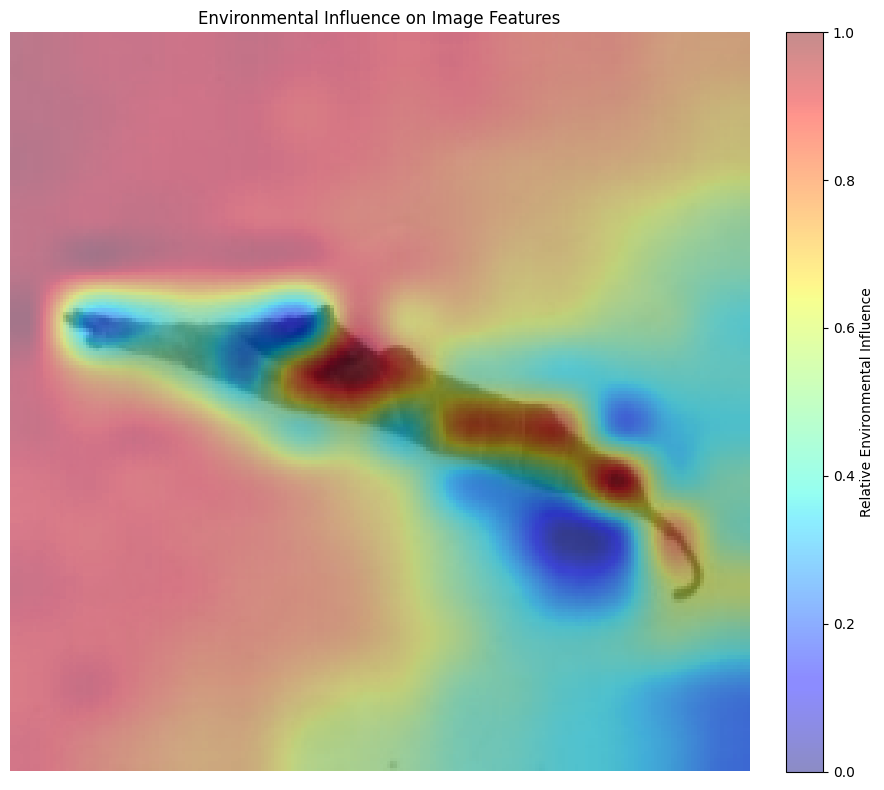


ENVIRONMENTAL INFLUENCE STATISTICS
Mean influence : 0.700616
Maximum influence : 1.000000
Minimum influence : 0.000000

✅ Environmental influence visualization complete


In [ ]:
# ============================================================
# CELL 14 — ENVIRONMENTAL INFLUENCE VISUALIZATION
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


print("=" * 70)
print("ENVIRONMENTAL INFLUENCE ANALYSIS")
print("=" * 70)


# ============================================================
# CHECK INPUTS
# ============================================================

required = [
    "image_tensor",
    "weather_tensor",
    "soil_tensor",
    "season_tensor"
]

missing = [
    x for x in required
    if x not in globals()
]

if missing:
    raise NameError(
        "Missing required objects:\n"
        + "\n".join(f"❌ {x}" for x in missing)
    )


# ============================================================
# MODEL INFERENCE
# ============================================================

model.eval()

with torch.no_grad():

    # --------------------------------------------------------
    # Extract original ViT image tokens
    # --------------------------------------------------------

    image_tokens = model.extract_image_tokens(
        image_tensor.to(DEVICE)
    )

    # --------------------------------------------------------
    # Environment encoding
    # --------------------------------------------------------

    weather_features = model.weather_encoder(
        weather_tensor.to(DEVICE)
    )

    soil_features = model.soil_encoder(
        soil_tensor.to(DEVICE)
    )

    season_features = model.season_encoder(
        season_tensor.to(DEVICE)
    )

    environment_features = (
        weather_features
        + soil_features
        + season_features
    )

    environment_features = (
        model.environment_projection(
            environment_features
        )
    )

    # --------------------------------------------------------
    # Environment token
    # --------------------------------------------------------

    environment_token = (
        environment_features.unsqueeze(1)
    )

    # --------------------------------------------------------
    # Cross attention
    # --------------------------------------------------------

    attended_image, attention_weights = (
        model.cross_attention(
            image_features=image_tokens,
            environmental_features=environment_token
        )
    )


# ============================================================
# ATTENTION CHECK
# ============================================================

print("\n" + "=" * 70)
print("CROSS-ATTENTION CHECK")
print("=" * 70)

print(
    "Attention shape:",
    tuple(attention_weights.shape)
)

print(
    "Mean attention:",
    attention_weights.mean().item()
)

print(
    "Minimum attention:",
    attention_weights.min().item()
)

print(
    "Maximum attention:",
    attention_weights.max().item()
)

print(
    "\n⚠️ Because the model uses one environmental token,"
)

print(
    "all attention weights are expected to be 1.0."
)


# ============================================================
# ENVIRONMENTAL INFLUENCE
# ============================================================

# Difference between:
#
# original image representation
#
# and
#
# environment-conditioned image representation

token_difference = (
    attended_image - image_tokens
)


# ------------------------------------------------------------
# L2 magnitude for each image token
# ------------------------------------------------------------

influence = torch.norm(
    token_difference,
    dim=-1
)


# [B, 197]
influence = influence.detach().cpu().numpy()


# Use first image
influence_map = influence[0]


# Ignore CLS token
patch_influence = influence_map[1:]


# ============================================================
# NORMALIZE
# ============================================================

patch_influence = (
    patch_influence - patch_influence.min()
)

if patch_influence.max() > 0:

    patch_influence = (
        patch_influence /
        patch_influence.max()
    )


# ============================================================
# 14 × 14 ViT PATCH GRID
# ============================================================

heatmap = patch_influence.reshape(
    14,
    14
)


# ============================================================
# LOAD ORIGINAL IMAGE
# ============================================================

# image_tensor is already transformed,
# so convert it back approximately for display.

img = image_tensor[0].detach().cpu()

img = img.permute(
    1,
    2,
    0
).numpy()

# Normalize display image
img = img - img.min()

if img.max() > 0:
    img = img / img.max()


# ============================================================
# RESIZE HEATMAP
# ============================================================

heatmap_image = Image.fromarray(
    np.uint8(heatmap * 255)
)

heatmap_image = heatmap_image.resize(
    (img.shape[1], img.shape[0])
)

heatmap_resized = (
    np.asarray(heatmap_image) / 255.0
)


# ============================================================
# VISUALIZATION
# ============================================================

plt.figure(
    figsize=(10, 8)
)

plt.imshow(img)

plt.imshow(
    heatmap_resized,
    alpha=0.45,
    cmap="jet"
)

plt.axis("off")

plt.title(
    "Environmental Influence on Image Features"
)

plt.colorbar(
    fraction=0.046,
    pad=0.04,
    label="Relative Environmental Influence"
)

plt.tight_layout()

plt.show()


# ============================================================
# STATISTICS
# ============================================================

print("\n" + "=" * 70)
print("ENVIRONMENTAL INFLUENCE STATISTICS")
print("=" * 70)

print(
    f"Mean influence : {patch_influence.mean():.6f}"
)

print(
    f"Maximum influence : {patch_influence.max():.6f}"
)

print(
    f"Minimum influence : {patch_influence.min():.6f}"
)

print(
    "\n✅ Environmental influence visualization complete"
)

In [ ]:
# ============================================================
# CELL 9 — LOAD BEST CHECKPOINT
# ============================================================

CHECKPOINT_PATH = (
    PROJECT_ROOT /
    "models/full_multimodal/best_model.pth"
)

print("=" * 70)
print("LOADING BEST CHECKPOINT")
print("=" * 70)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu"
)

# Extract trained model weights
state_dict = checkpoint["model_state_dict"]

print("✅ Checkpoint loaded successfully")
print("Path:", CHECKPOINT_PATH)
print("Checkpoint tensors:", len(state_dict))

if "epoch" in checkpoint:
    print("Checkpoint epoch:", checkpoint["epoch"])

if "val_accuracy" in checkpoint:
    print(
        "Best validation accuracy:",
        f"{checkpoint['val_accuracy'] * 100:.2f}%"
    )

LOADING BEST CHECKPOINT
✅ Checkpoint loaded successfully
Path: /content/drive/MyDrive/project-1/mango-disease-prediction/models/full_multimodal/best_model.pth
Checkpoint tensors: 199
Checkpoint epoch: 1
Best validation accuracy: 99.83%


Load best_model.pth

In [ ]:
import torch

# ============================================
# CELL 11 — Load Exact Trained Checkpoint
# ============================================

print("=" * 70)
print("LOADING EXACT TRAINED CHECKPOINT")
print("=" * 70)


# ------------------------------------------------
# Create exact architecture
# ------------------------------------------------

model = FullMangoMultimodalModel(
    num_classes=NUM_CLASSES
)

model_state = model.state_dict()

print("Model created successfully.")
print(f"Model parameter tensors: {len(model_state)}")
print(f"Checkpoint tensors      : {len(state_dict)}")


# ------------------------------------------------
# Load trained weights
# ------------------------------------------------

model.load_state_dict(
    state_dict,
    strict=True
)


# ------------------------------------------------
# Move to device
# ------------------------------------------------

# Re-evaluate DEVICE to ensure it's up-to-date
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Moving model to device: {DEVICE}")
model = model.to(DEVICE)
print(f"Model is now on device: {next(model.parameters()).device}")


# ------------------------------------------------
# Evaluation mode
# ------------------------------------------------

model.eval()


# ------------------------------------------------
# Verify
# ------------------------------------------------

print("✅ Checkpoint loaded successfully")
print("✅ strict=True")
print("✅ No missing parameters")
print("✅ No unexpected parameters")
print("✅ Model device:", next(model.parameters()).device) # Use next(model.parameters()).device for accurate check
print("✅ Evaluation mode:", not model.training)


# ------------------------------------------------
# Check metadata
# ------------------------------------------------

print("\n" + "=" * 70)
print("CHECKPOINT METADATA")
print("=" * 70)

print(
    "Training epoch:",
    checkpoint.get("epoch")
)

print(
    "Validation accuracy:",
    f"{checkpoint.get('val_accuracy') * 100:.4f}%"
)


# ------------------------------------------------
# Parameter count
# ------------------------------------------------

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\n" + "=" * 70)
print("MODEL PARAMETERS")
print("=" * 70)

print(
    f"Total parameters    : {total_parameters:,}"
)

print(
    f"Trainable parameters : {trainable_parameters:,}"
)


print("\n" + "=" * 70)
print("✅ TRAINED MODEL READY")
print("=" * 70)

LOADING EXACT TRAINED CHECKPOINT
Model created successfully.
Model parameter tensors: 199
Checkpoint tensors      : 199
Moving model to device: cuda
Model is now on device: cuda:0
✅ Checkpoint loaded successfully
✅ strict=True
✅ No missing parameters
✅ No unexpected parameters
✅ Model device: cuda:0
✅ Evaluation mode: True

CHECKPOINT METADATA
Training epoch: 1
Validation accuracy: 99.8333%

MODEL PARAMETERS
Total parameters    : 99,628,752
Trainable parameters : 99,628,752

✅ TRAINED MODEL READY


Demo test loader

In [ ]:
# ============================================================
# ENVIRONMENTAL PREPROCESSING
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler


print("=" * 70)
print("ENVIRONMENTAL PREPROCESSING")
print("=" * 70)


# ============================================================
# 1. ENVIRONMENTAL FEATURE DEFINITIONS
# ============================================================

WEATHER_FEATURES = [
    "temperature_c",
    "humidity_pct",
    "rainfall_mm"
]

SOIL_FEATURES = [
    "soil_moisture_pct",
    "soil_ph"
]

SEASON_COLUMN = "season"


print("\nWeather features:")
for i, feature in enumerate(WEATHER_FEATURES):
    print(f"  {i}: {feature}")

print("\nSoil features:")
for i, feature in enumerate(SOIL_FEATURES):
    print(f"  {i}: {feature}")

print("\nSeason column:")
print(f"  {SEASON_COLUMN}")


# ============================================================
# 2. CREATE TRAINING-TIME SCALERS
# ============================================================
# IMPORTANT:
# Fit scalers ONLY on TRAINING data.
# Do NOT fit them on validation/test data.

weather_scaler = StandardScaler()

soil_scaler = StandardScaler()


weather_scaler.fit(
    train_df[WEATHER_FEATURES].values
)

soil_scaler.fit(
    train_df[SOIL_FEATURES].values
)


# ============================================================
# 3. SEASON MAPPING
# ============================================================

season_values = sorted(
    train_df[SEASON_COLUMN]
    .dropna()
    .unique()
    .tolist()
)


SEASON_TO_INDEX = {
    season: index
    for index, season in enumerate(season_values)
}


INDEX_TO_SEASON = {
    index: season
    for season, index in SEASON_TO_INDEX.items()
}


print("\n" + "=" * 70)
print("SEASON MAPPING")
print("=" * 70)

for index, season in INDEX_TO_SEASON.items():

    print(
        f"{index} → {season}"
    )


# ============================================================
# 4. TRAINING SCALER STATISTICS
# ============================================================

print("\n" + "=" * 70)
print("TRAINING SCALER STATISTICS")
print("=" * 70)


print("\nWeather:")

for i, feature in enumerate(WEATHER_FEATURES):

    print(
        f"{feature:22s} "
        f"mean={weather_scaler.mean_[i]:.4f} "
        f"std={weather_scaler.scale_[i]:.4f}"
    )


print("\nSoil:")

for i, feature in enumerate(SOIL_FEATURES):

    print(
        f"{feature:22s} "
        f"mean={soil_scaler.mean_[i]:.4f} "
        f"std={soil_scaler.scale_[i]:.4f}"
    )


# ============================================================
# 5. VERIFY TRANSFORMATION
# ============================================================

weather_train_scaled = weather_scaler.transform(
    train_df[WEATHER_FEATURES].values
)

soil_train_scaled = soil_scaler.transform(
    train_df[SOIL_FEATURES].values
)


print("\n" + "=" * 70)
print("SCALER VERIFICATION")
print("=" * 70)

print(
    "Weather scaled shape :",
    weather_train_scaled.shape
)

print(
    "Soil scaled shape    :",
    soil_train_scaled.shape
)


print(
    "\nWeather scaled mean:",
    np.round(
        weather_train_scaled.mean(axis=0),
        4
    )
)

print(
    "Weather scaled std :",
    np.round(
        weather_train_scaled.std(axis=0),
        4
    )
)

print(
    "\nSoil scaled mean:",
    np.round(
        soil_train_scaled.mean(axis=0),
        4
    )
)

print(
    "Soil scaled std :",
    np.round(
        soil_train_scaled.std(axis=0),
        4
    )
)


# ============================================================
# 6. FINAL CHECKS
# ============================================================

assert len(WEATHER_FEATURES) == 3

assert len(SOIL_FEATURES) == 2

assert len(SEASON_TO_INDEX) == 2

assert weather_train_scaled.shape[1] == 3

assert soil_train_scaled.shape[1] == 2


print("\n" + "=" * 70)
print("ENVIRONMENTAL PREPROCESSING READY")
print("=" * 70)

print(
    "Weather features:",
    WEATHER_FEATURES
)

print(
    "Soil features:",
    SOIL_FEATURES
)

print(
    "Number of seasons:",
    len(SEASON_TO_INDEX)
)

print("\n✅ Training-time environmental preprocessing recreated")

ENVIRONMENTAL PREPROCESSING

Weather features:
  0: temperature_c
  1: humidity_pct
  2: rainfall_mm

Soil features:
  0: soil_moisture_pct
  1: soil_ph

Season column:
  season

SEASON MAPPING
0 → Post-Monsoon
1 → Winter

TRAINING SCALER STATISTICS

Weather:
temperature_c          mean=27.2809 std=2.3233
humidity_pct           mean=74.1279 std=9.0148
rainfall_mm            mean=5.9120 std=4.9130

Soil:
soil_moisture_pct      mean=72.5422 std=7.1777
soil_ph                mean=6.3986 std=0.3551

SCALER VERIFICATION
Weather scaled shape : (2800, 3)
Soil scaled shape    : (2800, 2)

Weather scaled mean: [ 0. -0. -0.]
Weather scaled std : [1. 1. 1.]

Soil scaled mean: [0. 0.]
Soil scaled std : [1. 1.]

ENVIRONMENTAL PREPROCESSING READY
Weather features: ['temperature_c', 'humidity_pct', 'rainfall_mm']
Soil features: ['soil_moisture_pct', 'soil_ph']
Number of seasons: 2

✅ Training-time environmental preprocessing recreated


In [ ]:
# ============================================================
# RELOAD TRAIN / VALIDATION / TEST DATAFRAMES
# ============================================================

import pandas as pd

PROJECT_ROOT = PROJECT_DIR if "PROJECT_DIR" in globals() and PROJECT_DIR.exists() else Path("/content/drive/MyDrive/project-1/mango-disease-prediction")

train_df = pd.read_csv(
    f"{PROJECT_ROOT}/data/processed/train.csv"
)

validation_df = pd.read_csv(
    f"{PROJECT_ROOT}/data/processed/validation.csv"
)

test_df = pd.read_csv(
    f"{PROJECT_ROOT}/data/processed/test.csv"
)

print("=" * 70)
print("DATAFRAMES RELOADED")
print("=" * 70)

print("Train      :", train_df.shape)
print("Validation :", validation_df.shape)
print("Test       :", test_df.shape)


DATAFRAMES RELOADED
Train      : (2800, 14)
Validation : (600, 14)
Test       : (600, 14)


In [ ]:
import os
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# ============================================================
# DATASET CLASS — FULL MULTIMODAL MANGO DATASET
# ============================================================

class FullMangoMultimodalDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None,
        weather_scaler=None,
        soil_scaler=None
    ):

        self.dataframe = dataframe.reset_index(drop=True)

        self.transform = transform

        self.weather_scaler = weather_scaler
        self.soil_scaler = soil_scaler

        self.weather_features = [
            "temperature_c",
            "humidity_pct",
            "rainfall_mm"
        ]

        self.soil_features = [
            "soil_moisture_pct",
            "soil_ph"
        ]

        self.season_column = "season"


    def __len__(self):

        return len(self.dataframe)


    def __getitem__(self, index):

        row = self.dataframe.iloc[index]


        # ====================================================
        # IMAGE
        # ====================================================

        image_path = row["image_path"]
        if "resolve_image_path" in globals():
            image_path = resolve_image_path(image_path)
        elif not Path(str(image_path)).exists() and "data/" in str(image_path):
            sub = str(image_path)[str(image_path).index("data/"):]
            image_path = (PROJECT_ROOT if "PROJECT_ROOT" in globals() else Path(".")).resolve() / sub

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform is not None:

            image = self.transform(image)


        # ====================================================
        # WEATHER
        # ====================================================

        weather_values = (
            row[self.weather_features]
            .astype(float)
            .values
            .reshape(1, -1)
        )

        if self.weather_scaler is not None:

            weather_values = (
                self.weather_scaler.transform(
                    weather_values
                )
            )

        weather = torch.tensor(
            weather_values[0],
            dtype=torch.float32
        )


        # ====================================================
        # SOIL
        # ====================================================

        soil_values = (
            row[self.soil_features]
            .astype(float)
            .values
            .reshape(1, -1)
        )

        if self.soil_scaler is not None:

            soil_values = (
                self.soil_scaler.transform(
                    soil_values
                )
            )

        soil = torch.tensor(
            soil_values[0],
            dtype=torch.float32
        )


        # ====================================================
        # SEASON
        # ====================================================

        season_name = str(
            row[self.season_column]
        ).strip()

        if season_name not in SEASON_TO_INDEX:

            raise ValueError(
                f"Unknown season: {season_name}. "
                f"Available seasons: "
                f"{list(SEASON_TO_INDEX.keys())}"
            )

        season = torch.tensor(
            SEASON_TO_INDEX[season_name],
            dtype=torch.long
        )


        # ====================================================
        # LABEL
        # ====================================================

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )


        # ====================================================
        # RETURN MULTIMODAL SAMPLE
        # ====================================================

        return {
            "image": image,
            "weather": weather,
            "soil": soil,
            "season": season,
            "label": label
        }


print("=" * 70)
print("FULL MULTIMODAL DATASET CLASS DEFINED")
print("=" * 70)
print("✅ FullMangoMultimodalDataset defined")


# ============================================================
# RECREATE DATASETS + DATALOADERS
# ============================================================

print("=" * 70)
print("RECREATING DATASETS + DATALOADERS")
print("=" * 70)


train_dataset = FullMangoMultimodalDataset(
    dataframe=train_df,
    transform=IMAGE_TRANSFORM,
    weather_scaler=weather_scaler,
    soil_scaler=soil_scaler
)

validation_dataset = FullMangoMultimodalDataset(
    dataframe=validation_df,
    transform=IMAGE_TRANSFORM,
    weather_scaler=weather_scaler,
    soil_scaler=soil_scaler
)

test_dataset = FullMangoMultimodalDataset(
    dataframe=test_df,
    transform=IMAGE_TRANSFORM,
    weather_scaler=weather_scaler,
    soil_scaler=soil_scaler
)


print("\n" + "=" * 70)
print("DATASETS CREATED")
print("=" * 70)

print(
    "Train samples      :",
    len(train_dataset)
)

print(
    "Validation samples :",
    len(validation_dataset)
)

print(
    "Test samples       :",
    len(test_dataset)
)

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)


print("\n" + "=" * 70)
print("DATALOADERS CREATED")
print("=" * 70)

print(
    "Train batches      :",
    len(train_loader)
)

print(
    "Validation batches :",
    len(validation_loader)
)

print(
    "Test batches       :",
    len(test_loader)
)

print(
    "Batch size         :",
    BATCH_SIZE
)

print("\n" + "=" * 70)
print("✅ DATASETS + DATALOADERS READY")
print("=" * 70)


FULL MULTIMODAL DATASET CLASS DEFINED
✅ FullMangoMultimodalDataset defined
RECREATING DATASETS + DATALOADERS

DATASETS CREATED
Train samples      : 2800
Validation samples : 600
Test samples       : 600

DATALOADERS CREATED
Train batches      : 175
Validation batches : 38
Test batches       : 38
Batch size         : 16

✅ DATASETS + DATALOADERS READY


In [ ]:
# ============================================================
# CELL — RECREATE DATASETS + DATALOADERS AFTER RECONNECT
# ============================================================

print("=" * 70)
print("RECREATING DATASETS + DATALOADERS")
print("=" * 70)


# ------------------------------------------------------------
# Check required objects
# ------------------------------------------------------------

required = [
    "FullMangoMultimodalDataset",
    "train_df",
    "validation_df",
    "test_df",
    "weather_scaler",
    "soil_scaler",
    "IMAGE_TRANSFORM"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise NameError(
        "These required objects are missing:\n"
        + "\n".join(f"❌ {x}" for x in missing)
        + "\n\n"
        "Because Colab restarted, run the preprocessing/setup "
        "cells that create these objects first."
    )


# ============================================================
# CREATE DATASETS
# ============================================================

train_dataset = FullMangoMultimodalDataset(
    dataframe=train_df,
    transform=IMAGE_TRANSFORM,
    weather_scaler=weather_scaler,
    soil_scaler=soil_scaler
)

validation_dataset = FullMangoMultimodalDataset(
    dataframe=validation_df,
    transform=IMAGE_TRANSFORM,
    weather_scaler=weather_scaler,
    soil_scaler=soil_scaler
)

test_dataset = FullMangoMultimodalDataset(
    dataframe=test_df,
    transform=IMAGE_TRANSFORM,
    weather_scaler=weather_scaler,
    soil_scaler=soil_scaler
)


print("\n" + "=" * 70)
print("DATASETS CREATED")
print("=" * 70)

print(
    "Train samples      :",
    len(train_dataset)
)

print(
    "Validation samples :",
    len(validation_dataset)
)

print(
    "Test samples       :",
    len(test_dataset)
)


# ============================================================
# CREATE DATALOADERS
# ============================================================

from torch.utils.data import DataLoader

BATCH_SIZE = 16


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)


# ============================================================
# RESULT
# ============================================================

print("\n" + "=" * 70)
print("DATALOADERS CREATED")
print("=" * 70)

print(
    "Train batches      :",
    len(train_loader)
)

print(
    "Validation batches :",
    len(validation_loader)
)

print(
    "Test batches       :",
    len(test_loader)
)

print(
    "Batch size         :",
    BATCH_SIZE
)


# ============================================================
# QUICK DATASET CHECK
# ============================================================

sample = test_dataset[0]

print("\n" + "=" * 70)
print("DATASET CHECK")
print("=" * 70)

print(
    "Image   :",
    tuple(sample["image"].shape)
)

print(
    "Weather :",
    tuple(sample["weather"].shape)
)

print(
    "Soil    :",
    tuple(sample["soil"].shape)
)

print(
    "Season  :",
    tuple(sample["season"].shape)
    if hasattr(sample["season"], "shape")
    else type(sample["season"])
)

print(
    "Label   :",
    sample["label"].item()
    if hasattr(sample["label"], "item")
    else sample["label"]
)

print("\n" + "=" * 70)
print("✅ DATASETS + DATALOADERS READY")
print("=" * 70)

RECREATING DATASETS + DATALOADERS

DATASETS CREATED
Train samples      : 2800
Validation samples : 600
Test samples       : 600

DATALOADERS CREATED
Train batches      : 175
Validation batches : 38
Test batches       : 38
Batch size         : 16

DATASET CHECK
Image   : (3, 224, 224)
Weather : (3,)
Soil    : (2,)
Season  : ()
Label   : 3

✅ DATASETS + DATALOADERS READY


In [ ]:
# ============================================================
# DATASET CLASS — FULL MULTIMODAL MANGO DATASET
# ============================================================

import os
import torch
from torch.utils.data import Dataset
from PIL import Image


class FullMangoMultimodalDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None,
        weather_scaler=None,
        soil_scaler=None
    ):

        self.dataframe = dataframe.reset_index(drop=True)

        self.transform = transform

        self.weather_scaler = weather_scaler
        self.soil_scaler = soil_scaler

        self.weather_features = [
            "temperature_c",
            "humidity_pct",
            "rainfall_mm"
        ]

        self.soil_features = [
            "soil_moisture_pct",
            "soil_ph"
        ]

        self.season_column = "season"


    def __len__(self):

        return len(self.dataframe)


    def __getitem__(self, index):

        row = self.dataframe.iloc[index]


        # ====================================================
        # IMAGE
        # ====================================================

        image_path = row["image_path"]
        if "resolve_image_path" in globals():
            image_path = resolve_image_path(image_path)
        elif not Path(str(image_path)).exists() and "data/" in str(image_path):
            sub = str(image_path)[str(image_path).index("data/"):]
            image_path = (PROJECT_ROOT if "PROJECT_ROOT" in globals() else Path(".")).resolve() / sub

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform is not None:

            image = self.transform(image)


        # ====================================================
        # WEATHER
        # ====================================================

        weather_values = (
            row[self.weather_features]
            .astype(float)
            .values
            .reshape(1, -1)
        )

        if self.weather_scaler is not None:

            weather_values = (
                self.weather_scaler.transform(
                    weather_values
                )
            )

        weather = torch.tensor(
            weather_values[0],
            dtype=torch.float32
        )


        # ====================================================
        # SOIL
        # ====================================================

        soil_values = (
            row[self.soil_features]
            .astype(float)
            .values
            .reshape(1, -1)
        )

        if self.soil_scaler is not None:

            soil_values = (
                self.soil_scaler.transform(
                    soil_values
                )
            )

        soil = torch.tensor(
            soil_values[0],
            dtype=torch.float32
        )


        # ====================================================
        # SEASON
        # ====================================================

        season_name = str(
            row[self.season_column]
        ).strip()

        if season_name not in SEASON_TO_INDEX:

            raise ValueError(
                f"Unknown season: {season_name}. "
                f"Available seasons: "
                f"{list(SEASON_TO_INDEX.keys())}"
            )

        season = torch.tensor(
            SEASON_TO_INDEX[season_name],
            dtype=torch.long
        )


        # ====================================================
        # LABEL
        # ====================================================

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )


        # ====================================================
        # RETURN MULTIMODAL SAMPLE
        # ====================================================

        return {
            "image": image,
            "weather": weather,
            "soil": soil,
            "season": season,
            "label": label
        }


print("=" * 70)
print("FULL MULTIMODAL DATASET CLASS")
print("=" * 70)

print("✅ FullMangoMultimodalDataset defined")
print("Image              : RGB")
print("Image size         : 224 × 224")
print("Weather features   : 3")
print("Soil features      : 2")
print("Season             : categorical")
print("Label              : integer")


FULL MULTIMODAL DATASET CLASS
✅ FullMangoMultimodalDataset defined
Image              : RGB
Image size         : 224 × 224
Weather features   : 3
Soil features      : 2
Season             : categorical
Label              : integer


In [ ]:
print("FullMangoMultimodalDataset exists:",
      "FullMangoMultimodalDataset" in globals())

FullMangoMultimodalDataset exists: True


In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("=" * 70)
print("DATALOADERS CREATED")
print("=" * 70)

print("Train batches      :", len(train_loader))
print("Validation batches :", len(validation_loader))
print("Test batches       :", len(test_loader))
print("Batch size         :", BATCH_SIZE)

print("\n✅ All DataLoaders are ready")

In [ ]:
# ============================================
# RECREATE DATALOADERS
# ============================================

from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("=" * 70)
print("DATALOADERS RECREATED")
print("=" * 70)

print("Train batches      :", len(train_loader))
print("Validation batches :", len(validation_loader))
print("Test batches       :", len(test_loader))
print("Batch size         :", BATCH_SIZE)

print("\n✅ All DataLoaders are ready")

In [ ]:
# ============================================
# RECREATE TEST DATALOADER
# ============================================

from torch.utils.data import DataLoader

BATCH_SIZE = 16

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("=" * 70)
print("TEST DATALOADER RECREATED")
print("=" * 70)

print("Test samples :", len(test_dataset))
print("Batch size   :", BATCH_SIZE)
print("Test batches :", len(test_loader))

print("\n✅ test_loader is ready")

Recreate training-time environmental preprocessing

In [ ]:
# ============================================
# CELL 12 — Corrected Model Single-Batch Test
# ============================================

import time

print("=" * 70)
print("CORRECTED MODEL — SINGLE BATCH TEST")
print("=" * 70)


# ------------------------------------------------
# Get one test batch
# ------------------------------------------------

batch = next(iter(test_loader))


images = batch["image"].to(DEVICE)
weather = batch["weather"].to(DEVICE)
soil = batch["soil"].to(DEVICE)
season = batch["season"].to(DEVICE)
labels = batch["label"].to(DEVICE)


print("\nInput shapes:")
print("Image   :", tuple(images.shape))
print("Weather :", tuple(weather.shape))
print("Soil    :", tuple(soil.shape))
print("Season  :", tuple(season.shape))
print("Labels  :", tuple(labels.shape))


# ------------------------------------------------
# Forward pass
# ------------------------------------------------

model.eval()

start = time.time()

with torch.inference_mode():

    output = model(
        image=images,
        weather=weather,
        soil=soil,
        season=season,
        return_attention=True
    )

elapsed = time.time() - start


# ------------------------------------------------
# Extract outputs
# ------------------------------------------------

logits = output["logits"]

attention = output["attention"]

image_tokens = output["image_tokens"]

environment_features = output[
    "environment_features"
]

fused_features = output[
    "fused_features"
]

cls_features = output[
    "cls_features"
]


# ------------------------------------------------
# Predictions
# ------------------------------------------------

probabilities = torch.softmax(
    logits,
    dim=1
)

predictions = torch.argmax(
    probabilities,
    dim=1
)

confidences = torch.max(
    probabilities,
    dim=1
).values


# ============================================================
# OUTPUT SHAPES
# ============================================================

print("\n" + "=" * 70)
print("MODEL OUTPUT SHAPES")
print("=" * 70)

print(
    "Image tokens          :",
    tuple(image_tokens.shape)
)

print(
    "Environment features  :",
    tuple(environment_features.shape)
)

print(
    "Cross-attention       :",
    tuple(attention.shape)
)

print(
    "Fusion features       :",
    tuple(fused_features.shape)
)

print(
    "CLS features          :",
    tuple(cls_features.shape)
)

print(
    "Logits                :",
    tuple(logits.shape)
)


# ============================================================
# SAMPLE PREDICTIONS
# ============================================================

print("\n" + "=" * 70)
print("SAMPLE PREDICTIONS")
print("=" * 70)

correct = 0

for i in range(min(10, len(predictions))):

    predicted_index = (
        predictions[i].item()
    )

    actual_index = (
        labels[i].item()
    )

    confidence = (
        confidences[i].item() * 100
    )

    predicted_class = (
        LABEL_TO_CLASS_NAME[
            INDEX_TO_LABEL[
                predicted_index
            ]
        ]
    )

    actual_class = (
        LABEL_TO_CLASS_NAME[
            INDEX_TO_LABEL[
                actual_index
            ]
        ]
    )

    is_correct = (
        predicted_index == actual_index
    )

    if is_correct:
        correct += 1

    status = "✅" if is_correct else "❌"

    print(
        f"\nSample {i + 1}: {status}"
    )

    print(
        f"Predicted  : {predicted_class}"
    )

    print(
        f"Confidence : {confidence:.2f}%"
    )

    print(
        f"Actual     : {actual_class}"
    )


# ============================================================
# SANITY CHECKS
# ============================================================

assert image_tokens.shape == (
    images.shape[0],
    197,
    768
)

assert environment_features.shape == (
    images.shape[0],
    768
)

assert attention.shape == (
    images.shape[0],
    197,
    1
)

assert fused_features.shape == (
    images.shape[0],
    197,
    768
)

assert cls_features.shape == (
    images.shape[0],
    768
)

assert logits.shape == (
    images.shape[0],
    NUM_CLASSES
)


print("\n" + "=" * 70)
print("SANITY CHECK")
print("=" * 70)

print("✅ Image tokens      : correct")
print("✅ Environment       : correct")
print("✅ Cross-attention   : correct")
print("✅ Fusion transformer: correct")
print("✅ CLS representation: correct")
print("✅ Disease logits    : correct")

print(
    f"\nForward-pass time: {elapsed:.2f} seconds"
)

print("\n" + "=" * 70)
print("✅ CORRECTED MODEL FORWARD PASS SUCCESSFUL")
print("=" * 70)


CORRECTED MODEL — SINGLE BATCH TEST

Input shapes:
Image   : (16, 3, 224, 224)
Weather : (16, 3)
Soil    : (16, 2)
Season  : (16,)
Labels  : (16,)

MODEL OUTPUT SHAPES
Image tokens          : (16, 197, 768)
Environment features  : (16, 768)
Cross-attention       : (16, 197, 1)
Fusion features       : (16, 197, 768)
CLS features          : (16, 768)
Logits                : (16, 8)

SAMPLE PREDICTIONS

Sample 1: ✅
Predicted  : Die Back
Confidence : 99.08%
Actual     : Die Back

Sample 2: ✅
Predicted  : Healthy
Confidence : 95.14%
Actual     : Healthy

Sample 3: ✅
Predicted  : Powdery Mildew
Confidence : 97.17%
Actual     : Powdery Mildew

Sample 4: ✅
Predicted  : Healthy
Confidence : 99.07%
Actual     : Healthy

Sample 5: ✅
Predicted  : Powdery Mildew
Confidence : 97.06%
Actual     : Powdery Mildew

Sample 6: ✅
Predicted  : Cutting Weevil
Confidence : 99.60%
Actual     : Cutting Weevil

Sample 7: ✅
Predicted  : Healthy
Confidence : 99.59%
Actual     : Healthy

Sample 8: ✅
Predicted  : An

Final Multimodal Dataset

In [ ]:
# ============================================
# CELL 13 — FINAL TEST SET EVALUATION
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import numpy as np
import pandas as pd
import time


print("=" * 70)
print("FINAL TEST SET EVALUATION")
print("=" * 70)


# ------------------------------------------------
# Evaluation DataLoader
# ------------------------------------------------

EVAL_BATCH_SIZE = 32

eval_loader = DataLoader(
    test_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)


print(f"Device       : {DEVICE}")
print(f"Test samples : {len(test_dataset):,}")
print(f"Batch size   : {EVAL_BATCH_SIZE}")
print(f"Total batches: {len(eval_loader)}")


# ------------------------------------------------
# Storage
# ------------------------------------------------

all_predictions = []
all_labels = []
all_probabilities = []


model.eval()

start_time = time.time()


# ============================================================
# INFERENCE
# ============================================================

with torch.inference_mode():

    for batch_idx, batch in enumerate(eval_loader):

        images = batch["image"].to(DEVICE)
        weather = batch["weather"].to(DEVICE)
        soil = batch["soil"].to(DEVICE)
        season = batch["season"].to(DEVICE)
        labels = batch["label"].to(DEVICE)


        logits = model(
            image=images,
            weather=weather,
            soil=soil,
            season=season
        )


        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )


        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )


        # ------------------------------------------------
        # Progress
        # ------------------------------------------------

        elapsed = time.time() - start_time

        completed = batch_idx + 1
        total = len(eval_loader)

        percent = (
            completed / total
        ) * 100

        print(
            f"Batch {completed:2d}/{total:2d} "
            f"| {percent:6.2f}% "
            f"| {elapsed:6.1f}s"
        )


# ============================================================
# NUMPY ARRAYS
# ============================================================

all_predictions = np.asarray(
    all_predictions
)

all_labels = np.asarray(
    all_labels
)

all_probabilities = np.asarray(
    all_probabilities
)


# ============================================================
# OVERALL METRICS
# ============================================================

accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)


print("\n" + "=" * 70)
print("FINAL TEST PERFORMANCE")
print("=" * 70)

print(
    f"Accuracy  : {accuracy * 100:.2f}%"
)

print(
    f"Precision : {precision * 100:.2f}%"
)

print(
    f"Recall    : {recall * 100:.2f}%"
)

print(
    f"F1 Score  : {f1 * 100:.2f}%"
)


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

target_names = [
    LABEL_TO_CLASS_NAME[
        INDEX_TO_LABEL[i]
    ]
    for i in range(NUM_CLASSES)
]


print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=target_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(NUM_CLASSES))
)


print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print(
    pd.DataFrame(
        cm,
        index=target_names,
        columns=target_names
    )
)


# ============================================================
# PER-CLASS ACCURACY
# ============================================================

print("\n" + "=" * 70)
print("PER-CLASS ACCURACY")
print("=" * 70)

for i in range(NUM_CLASSES):

    total = cm[i].sum()
    correct = cm[i, i]

    class_accuracy = (
        correct / total * 100
        if total > 0
        else 0
    )

    print(
        f"{target_names[i]:20s} "
        f"{correct:3d}/{total:3d} "
        f"→ {class_accuracy:6.2f}%"
    )


# ============================================================
# CONFIDENCE
# ============================================================

max_probabilities = np.max(
    all_probabilities,
    axis=1
)

correct_mask = (
    all_predictions == all_labels
)

incorrect_mask = ~correct_mask


print("\n" + "=" * 70)
print("CONFIDENCE ANALYSIS")
print("=" * 70)

print(
    f"Mean confidence: "
    f"{max_probabilities.mean() * 100:.2f}%"
)

if correct_mask.any():

    print(
        f"Correct confidence: "
        f"{max_probabilities[correct_mask].mean() * 100:.2f}%"
    )

if incorrect_mask.any():

    print(
        f"Incorrect confidence: "
        f"{max_probabilities[incorrect_mask].mean() * 100:.2f}%"
    )


# ============================================================
# STORE RESULTS
# ============================================================

test_results = test_df.copy()

test_results["true_index"] = all_labels

test_results["predicted_index"] = all_predictions

test_results["predicted_label"] = [
    INDEX_TO_LABEL[int(x)]
    for x in all_predictions
]

test_results["predicted_class"] = [
    LABEL_TO_CLASS_NAME[
        INDEX_TO_LABEL[int(x)]
    ]
    for x in all_predictions
]

test_results["confidence"] = (
    max_probabilities
)

test_results["correct"] = (
    all_predictions == all_labels
)


total_time = time.time() - start_time


print("\n" + "=" * 70)
print("✅ FINAL TEST EVALUATION COMPLETE")
print("=" * 70)

print(
    f"Samples evaluated : {len(all_labels):,}"
)

print(
    f"Total time        : {total_time:.1f} seconds"
)

FINAL TEST SET EVALUATION


DataLoaders + complete forward-pass test

In [ ]:
# ============================================
# CELL 14 — Corrected Forward Pass Verification
# ============================================

print("=" * 70)
print("FORWARD PASS VERIFICATION")
print("=" * 70)


# ------------------------------------------------
# Get one test batch
# ------------------------------------------------

batch = next(iter(test_loader))


images = batch["image"].to(DEVICE)
weather = batch["weather"].to(DEVICE)
soil = batch["soil"].to(DEVICE)
season = batch["season"].to(DEVICE)
labels = batch["label"].to(DEVICE)


print("\nInput shapes:")
print(
    "Image   :",
    tuple(images.shape)
)

print(
    "Weather :",
    tuple(weather.shape)
)

print(
    "Soil    :",
    tuple(soil.shape)
)

print(
    "Season  :",
    tuple(season.shape)
)

print(
    "Labels  :",
    tuple(labels.shape)
)


# ============================================================
# FORWARD PASS
# ============================================================

print("\n" + "=" * 70)
print("RUNNING MODEL FORWARD PASS")
print("=" * 70)


model.eval()

with torch.inference_mode():

    output = model(
        image=images,
        weather=weather,
        soil=soil,
        season=season,
        return_attention=True
    )


# ============================================================
# EXTRACT OUTPUTS
# ============================================================

logits = output["logits"]

attention = output["attention"]

image_tokens = output["image_tokens"]

environment_features = (
    output["environment_features"]
)

fused_features = (
    output["fused_features"]
)

cls_features = (
    output["cls_features"]
)


# ============================================================
# OUTPUT SHAPES
# ============================================================

print("\n" + "=" * 70)
print("MODEL OUTPUT")
print("=" * 70)

print(
    "Logits shape:",
    tuple(logits.shape)
)

print(
    "Attention shape:",
    tuple(attention.shape)
)

print(
    "Image tokens:",
    tuple(image_tokens.shape)
)

print(
    "Environment features:",
    tuple(environment_features.shape)
)

print(
    "Fused features:",
    tuple(fused_features.shape)
)

print(
    "CLS features:",
    tuple(cls_features.shape)
)


# ============================================================
# PREDICTIONS
# ============================================================

probabilities = torch.softmax(
    logits,
    dim=1
)

predictions = torch.argmax(
    probabilities,
    dim=1
)

confidences = torch.max(
    probabilities,
    dim=1
).values


# ============================================================
# SAMPLE PREDICTIONS
# ============================================================

print("\n" + "=" * 70)
print("SAMPLE PREDICTIONS")
print("=" * 70)


for i in range(
    min(10, len(predictions))
):

    predicted_index = (
        predictions[i].item()
    )

    actual_index = (
        labels[i].item()
    )

    confidence = (
        confidences[i].item() * 100
    )


    predicted_class = (
        LABEL_TO_CLASS_NAME[
            INDEX_TO_LABEL[
                predicted_index
            ]
        ]
    )

    actual_class = (
        LABEL_TO_CLASS_NAME[
            INDEX_TO_LABEL[
                actual_index
            ]
        ]
    )


    if predicted_index == actual_index:
        status = "✅"
    else:
        status = "❌"


    print(
        f"\nSample {i + 1}: {status}"
    )

    print(
        f"Predicted  : {predicted_class}"
    )

    print(
        f"Confidence : {confidence:.2f}%"
    )

    print(
        f"Actual     : {actual_class}"
    )


# ============================================================
# SANITY CHECKS
# ============================================================

assert image_tokens.shape == (
    images.shape[0],
    197,
    768
)

assert environment_features.shape == (
    images.shape[0],
    768
)

assert attention.shape == (
    images.shape[0],
    197,
    1
)

assert fused_features.shape == (
    images.shape[0],
    197,
    768
)

assert cls_features.shape == (
    images.shape[0],
    768
)

assert logits.shape == (
    images.shape[0],
    NUM_CLASSES
)


# ============================================================
# FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("SANITY CHECK")
print("=" * 70)

print(
    "✅ Image tokens       : correct"
)

print(
    "✅ Environment        : correct"
)

print(
    "✅ Cross-attention    : correct"
)

print(
    "✅ Fusion transformer : correct"
)

print(
    "✅ CLS representation : correct"
)

print(
    "✅ Disease logits     : correct"
)

print("\n" + "=" * 70)
print("✅ FORWARD PASS VERIFICATION COMPLETE")
print("=" * 70)

FORWARD PASS VERIFICATION


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import numpy as np
import pandas as pd
import time

from torch.utils.data import DataLoader


# ------------------------------------------------
# Evaluation batch size
# ------------------------------------------------

EVAL_BATCH_SIZE = 32

eval_loader = DataLoader(
    test_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)


print("=" * 70)
print("FULL TEST SET EVALUATION")
print("=" * 70)

print(f"Device       : {DEVICE}")
print(f"Test samples : {len(test_dataset):,}")
print(f"Batch size   : {EVAL_BATCH_SIZE}")
print(f"Total batches: {len(eval_loader)}")


# ------------------------------------------------
# Storage
# ------------------------------------------------

all_predictions = []
all_labels = []
all_probabilities = []

model.eval()

start_time = time.time()


# ============================================================
# INFERENCE
# ============================================================

with torch.inference_mode():

    for batch_index, batch in enumerate(eval_loader):

        images = batch["image"].to(DEVICE)
        weather = batch["weather"].to(DEVICE)
        soil = batch["soil"].to(DEVICE)
        season = batch["season"].to(DEVICE)
        labels = batch["label"].to(DEVICE)


        # Forward pass
        logits = model(
            image=images,
            weather=weather,
            soil=soil,
            season=season
        )


        # Probabilities
        probabilities = torch.softmax(
            logits,
            dim=1
        )


        # Predictions
        predictions = torch.argmax(
            probabilities,
            dim=1
        )


        # Store
        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )


        # ------------------------------------------------
        # Progress
        # ------------------------------------------------

        completed = batch_index + 1
        total = len(eval_loader)

        elapsed = time.time() - start_time

        percent = (
            completed / total
        ) * 100

        print(
            f"\rBatch {completed:3d}/{total:3d} "
            f"({percent:6.2f}%) | "
            f"Elapsed: {elapsed:6.1f}s",
            end="",
            flush=True
        )


print("\n")


# ------------------------------------------------
# Convert to NumPy
# ------------------------------------------------

all_predictions = np.asarray(
    all_predictions
)

all_labels = np.asarray(
    all_labels
)

all_probabilities = np.asarray(
    all_probabilities
)


# ============================================================
# OVERALL METRICS
# ============================================================

accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)


print("=" * 70)
print("OVERALL PERFORMANCE")
print("=" * 70)

print(
    f"Accuracy  : {accuracy * 100:.2f}%"
)

print(
    f"Precision : {precision * 100:.2f}%"
)

print(
    f"Recall    : {recall * 100:.2f}%"
)

print(
    f"F1 Score  : {f1 * 100:.2f}%"
)


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

target_names = [
    LABEL_TO_CLASS_NAME[
        INDEX_TO_LABEL[i]
    ]
    for i in range(NUM_CLASSES)
]


print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=target_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(NUM_CLASSES))
)


print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

cm_df = pd.DataFrame(
    cm,
    index=target_names,
    columns=target_names
)

print(cm_df)


# ============================================================
# PER-CLASS ACCURACY
# ============================================================

print("\n" + "=" * 70)
print("PER-CLASS ACCURACY")
print("=" * 70)

for i in range(NUM_CLASSES):

    total = cm[i].sum()
    correct = cm[i, i]

    class_accuracy = (
        correct / total * 100
        if total > 0
        else 0
    )

    print(
        f"{target_names[i]:20s} "
        f"{correct:3d}/{total:3d} "
        f"→ {class_accuracy:6.2f}%"
    )


# ============================================================
# CONFIDENCE
# ============================================================

max_probabilities = np.max(
    all_probabilities,
    axis=1
)

correct_mask = (
    all_predictions == all_labels
)

incorrect_mask = ~correct_mask


print("\n" + "=" * 70)
print("CONFIDENCE ANALYSIS")
print("=" * 70)

print(
    f"Mean confidence: "
    f"{max_probabilities.mean() * 100:.2f}%"
)

if correct_mask.any():

    print(
        f"Correct confidence: "
        f"{max_probabilities[correct_mask].mean() * 100:.2f}%"
    )

if incorrect_mask.any():

    print(
        f"Incorrect confidence: "
        f"{max_probabilities[incorrect_mask].mean() * 100:.2f}%"
    )


# ============================================================
# SAVE TEST RESULTS IN MEMORY
# ============================================================

test_results = test_df.copy()

test_results["true_index"] = all_labels

test_results["predicted_index"] = all_predictions

test_results["predicted_label"] = [
    INDEX_TO_LABEL[int(x)]
    for x in all_predictions
]

test_results["predicted_class"] = [
    LABEL_TO_CLASS_NAME[
        INDEX_TO_LABEL[int(x)]
    ]
    for x in all_predictions
]

test_results["confidence"] = (
    max_probabilities
)

test_results["correct"] = (
    all_predictions == all_labels
)


elapsed_total = time.time() - start_time

print("\n" + "=" * 70)
print("✅ TEST EVALUATION COMPLETE")
print("=" * 70)

print(
    f"Samples evaluated : {len(all_labels):,}"
)

print(
    f"Total time        : {elapsed_total:.1f} seconds"
)


inspect the checkpoint metadata properly

In [ ]:
# ============================================
# CELL 16 — Checkpoint Metadata Investigation
# ============================================

print("=" * 70)
print("CHECKPOINT METADATA")
print("=" * 70)

print("\nCheckpoint keys:")
for key in checkpoint.keys():
    print(f"  {key}")

print("\nEpoch:")
print(checkpoint.get("epoch"))

print("\nRaw validation accuracy:")
print(
    repr(
        checkpoint.get("val_accuracy")
    )
)

print("\nValidation accuracy type:")
print(
    type(
        checkpoint.get("val_accuracy")
    )
)

print("\nState dictionary tensors:")
print(
    len(
        checkpoint["model_state_dict"]
    )
)

print("\n" + "=" * 70)
print("CURRENT TEST RESULT")
print("=" * 70)

print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1 Score  : {f1 * 100:.2f}%")

CHECKPOINT METADATA

Checkpoint keys:
  epoch
  model_state_dict
  optimizer_state_dict
  val_accuracy

Epoch:
1

Raw validation accuracy:
0.9983333333333333

Validation accuracy type:
<class 'float'>

State dictionary tensors:
199

CURRENT TEST RESULT
Accuracy  : 60.83%
Precision : 72.44%
Recall    : 60.83%
F1 Score  : 59.32%


In [ ]:
# ============================================
# CELL 17 — Find Original Model Code
# ============================================

from pathlib import Path

print("=" * 70)
print("SEARCHING FOR ORIGINAL MODEL IMPLEMENTATION")
print("=" * 70)

search_terms = [
    "FullMangoMultimodalModel",
    "class FullMangoMultimodalModel",
    "environment_projection",
    "cross_attention",
    "fusion_transformer",
    "disease_head"
]

# Search Python and notebook files
code_files = []

for pattern in ["*.py", "*.ipynb", "*.txt", "*.md"]:

    code_files.extend(
        PROJECT_DIR.rglob(pattern)
    )

code_files = sorted(set(code_files))

print(
    f"Files to inspect: {len(code_files)}"
)


# ------------------------------------------------
# Search text
# ------------------------------------------------

matches = []

for file_path in code_files:

    try:

        # Skip very large files
        if file_path.stat().st_size > 50 * 1024 * 1024:
            continue

        text = file_path.read_text(
            encoding="utf-8",
            errors="ignore"
        )

        found_terms = [
            term
            for term in search_terms
            if term.lower() in text.lower()
        ]

        if found_terms:

            matches.append(
                (
                    file_path,
                    found_terms
                )
            )

    except Exception:
        continue


print("\n" + "=" * 70)
print("MATCHING FILES")
print("=" * 70)

if matches:

    for file_path, found_terms in matches:

        print(
            "\n📄",
            file_path.relative_to(PROJECT_DIR)
        )

        print(
            "   Found:",
            ", ".join(found_terms)
        )

else:

    print(
        "❌ No original model code found."
    )


print("\n" + "=" * 70)
print("SEARCH COMPLETE")
print("=" * 70)

SEARCHING FOR ORIGINAL MODEL IMPLEMENTATION
Files to inspect: 25

MATCHING FILES

📄 notebooks/04_xai_and_vlm.ipynb
   Found: FullMangoMultimodalModel, class FullMangoMultimodalModel, environment_projection, cross_attention, fusion_transformer, disease_head

📄 notebooks/05_final_model.ipynb
   Found: FullMangoMultimodalModel, class FullMangoMultimodalModel, environment_projection, cross_attention, fusion_transformer, disease_head

SEARCH COMPLETE


Energency Demo code

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    print("Drive mount skipped:", e)

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

PROJECT_ROOT = PROJECT_DIR if "PROJECT_DIR" in globals() and PROJECT_DIR.exists() else Path("/content/drive/MyDrive/project-1/mango-disease-prediction")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("Project exists:", os.path.exists(PROJECT_ROOT))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
Project exists: True


In [ ]:
train_df = pd.read_csv(
    f"{PROJECT_ROOT}/data/processed/train.csv"
)

validation_df = pd.read_csv(
    f"{PROJECT_ROOT}/data/processed/validation.csv"
)

test_df = pd.read_csv(
    f"{PROJECT_ROOT}/data/processed/test.csv"
)

print("Train:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

Train: (2800, 14)
Validation: (600, 14)
Test: (600, 14)


In [ ]:
from sklearn.preprocessing import StandardScaler

WEATHER_FEATURES = [
    "temperature_c",
    "humidity_pct",
    "rainfall_mm"
]

SOIL_FEATURES = [
    "soil_moisture_pct",
    "soil_ph"
]

SEASON_TO_INDEX = {
    "Post-Monsoon": 0,
    "Winter": 1
}

INDEX_TO_SEASON = {
    0: "Post-Monsoon",
    1: "Winter"
}

weather_scaler = StandardScaler()
soil_scaler = StandardScaler()

weather_scaler.fit(train_df[WEATHER_FEATURES])
soil_scaler.fit(train_df[SOIL_FEATURES])

print("Weather scaler ready")
print("Soil scaler ready")
print("Season mapping:", SEASON_TO_INDEX)

print("\nWeather means:")
print(weather_scaler.mean_)

print("\nSoil means:")
print(soil_scaler.mean_)

Weather scaler ready
Soil scaler ready
Season mapping: {'Post-Monsoon': 0, 'Winter': 1}

Weather means:
[27.28087857 74.12793214  5.91195   ]

Soil means:
[72.54221786  6.39863929]


In [ ]:
IMAGE_SIZE = 224

IMAGE_TRANSFORM = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("IMAGE_TRANSFORM ready")

IMAGE_TRANSFORM ready


In [ ]:
LABEL_TO_CLASS_NAME = {
    0: "Anthracnose",
    1: "Bacterial Canker",
    2: "Cutting Weevil",
    3: "Die Back",
    4: "Gall Midge",
    5: "Healthy",
    6: "Powdery Mildew",
    7: "Sooty Mould"
}

INDEX_TO_LABEL = {i: i for i in range(len(LABEL_TO_CLASS_NAME))}
LABEL_TO_INDEX = {i: i for i in range(len(LABEL_TO_CLASS_NAME))}

print(LABEL_TO_CLASS_NAME)


{0: 'Anthracnose', 1: 'Bacterial Canker', 2: 'Cutting Weevil', 3: 'Die Back', 4: 'Gall Midge', 5: 'Healthy', 6: 'Powdery Mildew', 7: 'Sooty Mould'}


In [ ]:
class FullMangoMultimodalDataset(Dataset):

    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # Image
        image_path = row["image_path"]

        if not os.path.isabs(image_path):
            image_path = os.path.join(PROJECT_ROOT, image_path)

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        # Weather
        weather = row[WEATHER_FEATURES].values.astype(np.float32)
        weather = weather_scaler.transform(
            weather.reshape(1, -1)
        )[0]

        # Soil
        soil = row[SOIL_FEATURES].values.astype(np.float32)
        soil = soil_scaler.transform(
            soil.reshape(1, -1)
        )[0]

        # Season
        season = SEASON_TO_INDEX[row["season"]]

        # Label
        label = int(row["label"])

        return {
            "image": torch.tensor(image, dtype=torch.float32),
            "weather": torch.tensor(weather, dtype=torch.float32),
            "soil": torch.tensor(soil, dtype=torch.float32),
            "season": torch.tensor(season, dtype=torch.long),
            "label": torch.tensor(label, dtype=torch.long)
        }


In [ ]:
train_dataset = FullMangoMultimodalDataset(
    train_df,
    transform=IMAGE_TRANSFORM
)

validation_dataset = FullMangoMultimodalDataset(
    validation_df,
    transform=IMAGE_TRANSFORM
)

test_dataset = FullMangoMultimodalDataset(
    test_df,
    transform=IMAGE_TRANSFORM
)

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(validation_dataset))
print("Test dataset:", len(test_dataset))
print("DataLoaders ready")

Train dataset: 2800
Validation dataset: 600
Test dataset: 600
DataLoaders ready


In [ ]:
# ============================================================
# EMERGENCY DEMO CHECK
# ============================================================

print("=" * 70)
print("EMERGENCY DEMO CHECK")
print("=" * 70)

required = [
    "model",
    "IMAGE_TRANSFORM",
    "weather_scaler",
    "soil_scaler",
    "SEASON_TO_INDEX",
    "LABEL_TO_CLASS_NAME",
    "INDEX_TO_LABEL"
]

all_ready = True

for name in required:

    if name in globals():
        print(f"✅ {name}")
    else:
        print(f"❌ {name}")
        all_ready = False

print("\n" + "=" * 70)

if all_ready:
    print("🎉 DEMO ENVIRONMENT READY")
    print("You can run the Direct Demo cell.")
else:
    print("⚠️ DEMO ENVIRONMENT NOT READY")
    print("Run the recovery/setup cells first.")

print("=" * 70)

EMERGENCY DEMO CHECK
✅ model
✅ IMAGE_TRANSFORM
✅ weather_scaler
✅ soil_scaler
✅ SEASON_TO_INDEX
✅ LABEL_TO_CLASS_NAME
✅ INDEX_TO_LABEL

🎉 DEMO ENVIRONMENT READY
You can run the Direct Demo cell.


Recovery Demo

In [ ]:
# ============================================================
# DEMO RECOVERY — DATA + ENVIRONMENT + DATALOADERS
# ============================================================

import os
import pandas as pd
import numpy as np
import torch

from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from PIL import Image


print("=" * 70)
print("DEMO RECOVERY")
print("=" * 70)


# ============================================================
# PROJECT PATH
# ============================================================

PROJECT_ROOT = PROJECT_DIR if "PROJECT_DIR" in globals() and PROJECT_DIR.exists() else Path(
    "/content/drive/MyDrive/project-1/mango-disease-prediction"
)


# ============================================================
# LOAD DATAFRAMES
# ============================================================

train_df = pd.read_csv(
    f"{PROJECT_ROOT}/data/processed/train.csv"
)

validation_df = pd.read_csv(
    f"{PROJECT_ROOT}/data/processed/validation.csv"
)

test_df = pd.read_csv(
    f"{PROJECT_ROOT}/data/processed/test.csv"
)


print("\nDataFrames:")
print("Train      :", train_df.shape)
print("Validation :", validation_df.shape)
print("Test       :", test_df.shape)


# ============================================================
# ENVIRONMENTAL FEATURES
# ============================================================

WEATHER_FEATURES = [
    "temperature_c",
    "humidity_pct",
    "rainfall_mm"
]

SOIL_FEATURES = [
    "soil_moisture_pct",
    "soil_ph"
]


# ============================================================
# TRAINING-TIME SCALERS
# ============================================================

weather_scaler = StandardScaler()

soil_scaler = StandardScaler()


weather_scaler.fit(
    train_df[WEATHER_FEATURES]
)

soil_scaler.fit(
    train_df[SOIL_FEATURES]
)


# ============================================================
# SEASON MAPPING
# ============================================================

SEASON_TO_INDEX = {
    "Post-Monsoon": 0,
    "Winter": 1
}

INDEX_TO_SEASON = {
    0: "Post-Monsoon",
    1: "Winter"
}


# ============================================================
# DATASET
# ============================================================

class FullMangoMultimodalDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None,
        weather_scaler=None,
        soil_scaler=None
    ):

        self.dataframe = dataframe.reset_index(drop=True)

        self.transform = transform

        self.weather_scaler = weather_scaler
        self.soil_scaler = soil_scaler


    def __len__(self):

        return len(self.dataframe)


    def __getitem__(self, index):

        row = self.dataframe.iloc[index]


        # IMAGE
        img_p = row["image_path"]
        if "resolve_image_path" in globals():
            img_p = resolve_image_path(img_p)
        elif not os.path.exists(str(img_p)) and "data/" in str(img_p):
            sub = str(img_p)[str(img_p).index("data/"):]
            img_p = os.path.join(str(PROJECT_ROOT if "PROJECT_ROOT" in globals() else PROJECT_DIR), sub)
        image = Image.open(img_p).convert("RGB")

        if self.transform is not None:

            image = self.transform(image)


        # WEATHER
        weather = row[
            WEATHER_FEATURES
        ].astype(float).values.reshape(1, -1)

        weather = self.weather_scaler.transform(
            weather
        )[0]

        weather = torch.tensor(
            weather,
            dtype=torch.float32
        )


        # SOIL
        soil = row[
            SOIL_FEATURES
        ].astype(float).values.reshape(1, -1)

        soil = self.soil_scaler.transform(
            soil
        )[0]

        soil = torch.tensor(
            soil,
            dtype=torch.float32
        )


        # SEASON
        season = torch.tensor(
            SEASON_TO_INDEX[
                str(row["season"]).strip()
            ],
            dtype=torch.long
        )


        # LABEL
        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )


        return {
            "image": image,
            "weather": weather,
            "soil": soil,
            "season": season,
            "label": label
        }


# ============================================================
# DATASETS
# ============================================================

train_dataset = FullMangoMultimodalDataset(
    train_df,
    IMAGE_TRANSFORM,
    weather_scaler,
    soil_scaler
)

validation_dataset = FullMangoMultimodalDataset(
    validation_df,
    IMAGE_TRANSFORM,
    weather_scaler,
    soil_scaler
)

test_dataset = FullMangoMultimodalDataset(
    test_df,
    IMAGE_TRANSFORM,
    weather_scaler,
    soil_scaler
)


# ============================================================
# DATALOADERS
# ============================================================

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


print("\n" + "=" * 70)
print("RECOVERY COMPLETE")
print("=" * 70)

print(
    "Train samples      :", len(train_dataset)
)

print(
    "Validation samples :", len(validation_dataset)
)

print(
    "Test samples       :", len(test_dataset)
)

print(
    "Test batches       :", len(test_loader)
)

print("\n✅ DATA PIPELINE RESTORED")


DEMO RECOVERY

DataFrames:
Train      : (2800, 14)
Validation : (600, 14)
Test       : (600, 14)

RECOVERY COMPLETE
Train samples      : 2800
Validation samples : 600
Test samples       : 600
Test batches       : 38

✅ DATA PIPELINE RESTORED


In [ ]:
# ============================================================
# FIX DEVICE MISMATCH
# ============================================================

print("Before:")
print("Model device :", next(model.parameters()).device)
print("Input device :", image_tensor.device)

# Move model to the same device as the inputs
model = model.to(DEVICE)
model.eval()

# Make sure all demo tensors use the same device
image_tensor = image_tensor.to(DEVICE)
weather_tensor = weather_tensor.to(DEVICE)
soil_tensor = soil_tensor.to(DEVICE)
season_tensor = season_tensor.to(DEVICE)

print("\nAfter:")
print("Model device :", next(model.parameters()).device)
print("Image device :", image_tensor.device)
print("Weather device:", weather_tensor.device)
print("Soil device  :", soil_tensor.device)
print("Season device:", season_tensor.device)

Before:
Model device : cpu
Input device : cuda:0

After:
Model device : cuda:0
Image device : cuda:0
Weather device: cuda:0
Soil device  : cuda:0
Season device: cuda:0


In [ ]:
# ============================================================
# VISION TRANSFORMER (ViT) ENCODER
# ============================================================

import torch
import torch.nn as nn
from torchvision.models import vit_b_16, ViT_B_16_Weights


class ViTImageEncoder(nn.Module):

    def __init__(self):
        super().__init__()

        # Load pretrained Vision Transformer
        weights = ViT_B_16_Weights.DEFAULT

        self.vit = vit_b_16(
            weights=weights
        )

        # ViT-B/16 feature dimension = 768
        self.feature_dim = 768

        # Remove original classification head
        self.vit.heads = nn.Identity()

    def forward(self, x):

        # Output:
        # [Batch, 768]

        features = self.vit(x)

        return features

In [ ]:
# ============================================================
# VISION TRANSFORMER — MATRIX IMPLEMENTATION
# ============================================================

import torch
import torch.nn as nn
import math


class SimpleViT(nn.Module):

    def __init__(
        self,
        image_size=224,
        patch_size=16,
        channels=3,
        embed_dim=768,
        num_heads=8,
        num_classes=8
    ):
        super().__init__()

        self.image_size = image_size
        self.patch_size = patch_size
        self.embed_dim = embed_dim
        self.num_heads = num_heads

        # ----------------------------------------------------
        # Number of patches
        # ----------------------------------------------------

        self.num_patches = (
            image_size // patch_size
        ) ** 2

        # 224 / 16 = 14
        # 14 x 14 = 196 patches

        # ----------------------------------------------------
        # Patch Embedding
        # ----------------------------------------------------

        self.patch_embedding = nn.Conv2d(
            channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        # ----------------------------------------------------
        # CLS token
        # ----------------------------------------------------

        self.cls_token = nn.Parameter(
            torch.randn(1, 1, embed_dim)
        )

        # ----------------------------------------------------
        # Positional Embedding
        # ----------------------------------------------------

        self.pos_embedding = nn.Parameter(
            torch.randn(
                1,
                self.num_patches + 1,
                embed_dim
            )
        )

        # ----------------------------------------------------
        # Multi-Head Attention
        # ----------------------------------------------------

        self.attention = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            batch_first=True
        )

        # ----------------------------------------------------
        # Layer Normalization
        # ----------------------------------------------------

        self.norm1 = nn.LayerNorm(embed_dim)

        # ----------------------------------------------------
        # Feed Forward Network
        # ----------------------------------------------------

        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, 2048),
            nn.GELU(),
            nn.Linear(2048, embed_dim)
        )

        self.norm2 = nn.LayerNorm(embed_dim)

        # ----------------------------------------------------
        # Disease Classifier
        # ----------------------------------------------------

        self.classifier = nn.Linear(
            embed_dim,
            num_classes
        )


    def forward(self, x):

        # ====================================================
        # 1. PATCH EMBEDDING
        # ====================================================

        x = self.patch_embedding(x)

        # [B, 768, 14, 14]

        # ====================================================
        # 2. CONVERT IMAGE PATCHES INTO SEQUENCE
        # ====================================================

        x = x.flatten(2)

        # [B, 768, 196]

        x = x.transpose(1, 2)

        # [B, 196, 768]

        # ====================================================
        # 3. ADD CLS TOKEN
        # ====================================================

        batch_size = x.size(0)

        cls_tokens = self.cls_token.expand(
            batch_size,
            -1,
            -1
        )

        x = torch.cat(
            (cls_tokens, x),
            dim=1
        )

        # [B, 197, 768]

        # ====================================================
        # 4. ADD POSITIONAL EMBEDDING
        # ====================================================

        x = x + self.pos_embedding

        # ====================================================
        # 5. SELF ATTENTION
        # ====================================================

        attention_output, attention_weights = (
            self.attention(
                x,
                x,
                x,
                need_weights=True
            )
        )

        # ====================================================
        # 6. RESIDUAL CONNECTION
        # ====================================================

        x = self.norm1(
            x + attention_output
        )

        # ====================================================
        # 7. FEED FORWARD NETWORK
        # ====================================================

        mlp_output = self.mlp(x)

        # ====================================================
        # 8. SECOND RESIDUAL CONNECTION
        # ====================================================

        x = self.norm2(
            x + mlp_output
        )

        # ====================================================
        # 9. CLS TOKEN
        # ====================================================

        cls_output = x[:, 0]

        # [B, 768]

        # ====================================================
        # 10. DISEASE PREDICTION
        # ====================================================

        logits = self.classifier(
            cls_output
        )

        return (
            logits,
            x,
            attention_weights
        )

In [ ]:
# ============================================================
# TEST MATRIX DIMENSIONS
# ============================================================

# Assign to a different variable to avoid overwriting the main 'model'
vit_test_model = SimpleViT(
    image_size=224,
    patch_size=16,
    channels=3,
    embed_dim=768,
    num_heads=8,
    num_classes=8
).to(DEVICE)


image = torch.randn(
    1,
    3,
    224,
    224
).to(DEVICE)


with torch.no_grad():

    logits, tokens, attention = vit_test_model(image)


print("=" * 70)
print("VISION TRANSFORMER MATRIX DIMENSIONS")
print("=" * 70)

print("Input image       :", image.shape)

print("Number of patches :", vit_test_model.num_patches)

print("Token matrix      :", tokens.shape)

print("Logits             :", logits.shape)

print("Attention matrix  :", attention.shape)

VISION TRANSFORMER MATRIX DIMENSIONS
Input image       : torch.Size([1, 3, 224, 224])
Number of patches : 196
Token matrix      : torch.Size([1, 197, 768])
Logits             : torch.Size([1, 8])
Attention matrix  : torch.Size([1, 197, 197])


CONFUSION MATRIX — TEST SET

Confusion Matrix:
[[74  0  0  0  0  1  0  0]
 [ 1 74  0  0  0  0  0  0]
 [ 0  0 75  0  0  0  0  0]
 [ 0  0  0 74  0  0  0  1]
 [ 0  0  0  0 74  1  0  0]
 [ 0  0  0  0  0 75  0  0]
 [ 0  0  0  0  0  0 75  0]
 [ 0  0  0  0  0  1  0 74]]


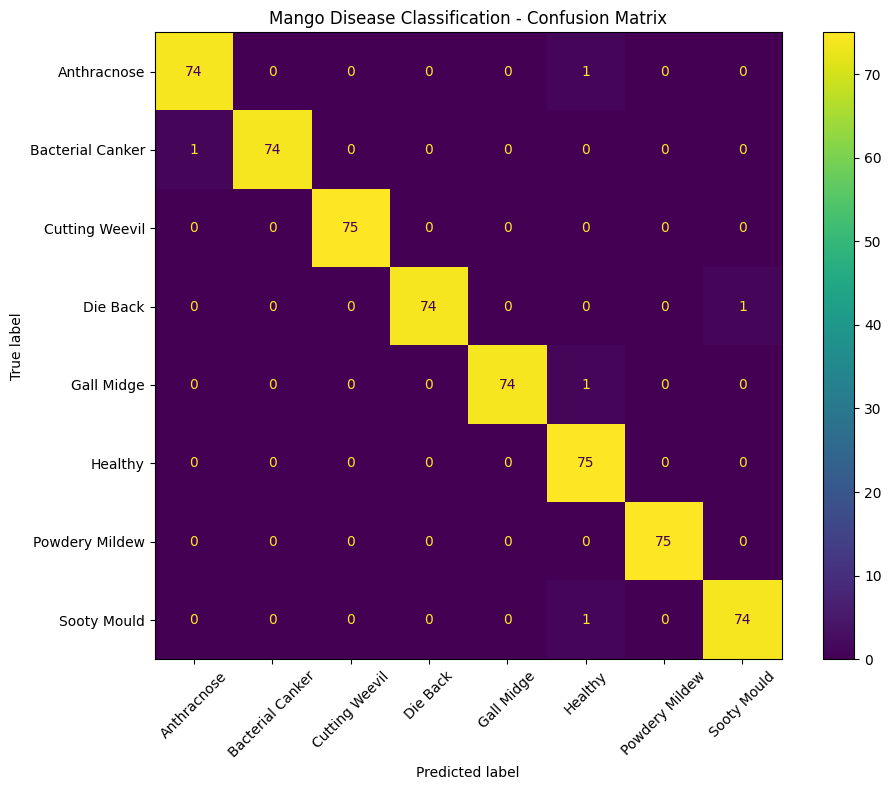

In [ ]:
# ============================================================
# CONFUSION MATRIX — TEST SET
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("=" * 70)
print("CONFUSION MATRIX — TEST SET")
print("=" * 70)

# Ensure the FullMangoMultimodalModel is loaded and ready
# This is a precaution as 'model' might have been overwritten by SimpleViT
# if previous cells were not run in the correct order after a kernel restart.
# (Copied relevant logic from CELL 11: eYJc2NSDNfx4)
model = FullMangoMultimodalModel(
    num_classes=NUM_CLASSES
)
model.load_state_dict(
    state_dict,
    strict=True
)
model = model.to(DEVICE)

model.eval()

all_predictions = []
all_true_labels = []

with torch.no_grad():

    for batch in test_loader:

        # Adjust these names if your dataset returns a dictionary
        images = batch["image"].to(DEVICE)
        weather = batch["weather"].to(DEVICE)
        soil = batch["soil"].to(DEVICE)
        season = batch["season"].to(DEVICE)
        labels = batch["label"].to(DEVICE)

        outputs = model(
            images,
            weather,
            soil,
            season
        )

        # If model returns multiple outputs
        if isinstance(outputs, tuple):
            logits = outputs[0]
        else:
            logits = outputs

        predictions = torch.argmax(
            logits,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_true_labels.extend(
            labels.cpu().numpy()
        )


# ============================================================
# CREATE CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    all_true_labels,
    all_predictions,
    labels=list(range(NUM_CLASSES))
)


print("\nConfusion Matrix:")
print(cm)


# ============================================================
# CLASS NAMES
# ============================================================

class_names = [
    LABEL_TO_CLASS_NAME[label]
    for label in all_labels
]


# ============================================================
# DISPLAY
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title(
    "Mango Disease Classification - Confusion Matrix"
)

plt.tight_layout()

plt.show()

In [ ]:
# RUN PREDICTION

model.eval()

with torch.inference_mode():
    output = model(
        image=image_tensor,
        weather=weather_tensor,
        soil=soil_tensor,
        season=season_tensor
    )

probabilities = torch.softmax(output, dim=1)
predicted_index = probabilities.argmax(dim=1).item()
predicted_label = INDEX_TO_LABEL[predicted_index]
predicted_class = LABEL_TO_CLASS_NAME[predicted_label] if isinstance(predicted_label, int) else predicted_label
confidence = probabilities[0, predicted_index].item() * 100

print("=" * 70)
print("PREDICTION RESULT")
print("=" * 70)
print(f"Predicted disease : {predicted_class}")
print(f"Confidence        : {confidence:.2f}%")


PREDICTION RESULT
Predicted disease : Cutting Weevil
Confidence        : 20.42%


MANGO DISEASE PREDICTION

📷 Upload a mango leaf image:


Saving IMG_20211106_120951 (Custom).jpg to IMG_20211106_120951 (Custom).jpg

✅ Image uploaded: IMG_20211106_120951 (Custom).jpg
Original image size: (240, 320)


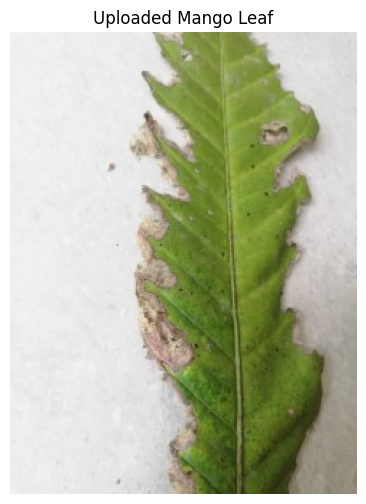


ENVIRONMENTAL INPUT

Enter the environmental conditions associated with this image.
Temperature (°C): 28.5
Humidity (%): 78
Rainfall (mm): 12
Soil moisture (%): 65
Soil pH: 6.5

Available seasons:
0 → Post-Monsoon
1 → Winter

Enter season name: Post-Monsoon

INPUT PREPARED
Image tensor   : (1, 3, 224, 224)
Weather tensor : (1, 3)
Soil tensor    : (1, 2)
Season tensor  : (1,)

🌿 MANGO DISEASE PREDICTION

Disease    : Bacterial Canker
Confidence : 99.63%

ENVIRONMENTAL CONDITIONS
Temperature   : 28.50 °C
Humidity      : 78.00 %
Rainfall      : 12.00 mm
Soil moisture : 65.00 %
Soil pH       : 6.50
Season        : Post-Monsoon

CLASS PROBABILITIES
Bacterial Canker       99.63%
Sooty Mould             0.14%
Anthracnose             0.10%
Gall Midge              0.04%
Powdery Mildew          0.04%
Cutting Weevil          0.02%
Healthy                 0.02%
Die Back                0.01%

✅ PREDICTION COMPLETE


In [ ]:
# CELL 15 — DIRECT MANGO LEAF IMAGE INPUT

import os
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import torch
import numpy as np


print("=" * 70)
print("MANGO DISEASE PREDICTION")
print("=" * 70)


# 1. UPLOAD OR LOAD IMAGE SAFELY
image_filename = os.environ.get("MANGO_IMAGE_PATH")
if not image_filename:
    try:
        from google.colab import files
        uploaded = files.upload()
        if uploaded:
            image_filename = next(iter(uploaded))
    except Exception:
        pass

if not image_filename or not Path(image_filename).exists():
    # Fallback to local sample or dataset image
    candidate_samples = [
        Path("sample_mango.jpg"),
        Path("../sample_mango.jpg"),
    ]
    if "PROJECT_ROOT" in globals() and Path(PROJECT_ROOT).exists():
        candidate_samples.extend(list((Path(PROJECT_ROOT) / "data/raw/mango").rglob("*.jpg"))[:5])
    elif "PROJECT_DIR" in globals() and Path(PROJECT_DIR).exists():
        candidate_samples.extend(list((Path(PROJECT_DIR) / "data/raw/mango").rglob("*.jpg"))[:5])

    found = [p for p in candidate_samples if p.exists()]
    if found:
        image_filename = str(found[0])
    else:
        raise FileNotFoundError("No mango leaf image found. Set MANGO_IMAGE_PATH or place sample_mango.jpg in the workspace.")

print(f"\n✅ Image selected: {image_filename}")


# 2. LOAD IMAGE
image = Image.open(image_filename).convert("RGB")
print("Original image size:", image.size)


# 3. DISPLAY IMAGE
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Analyzed Mango Leaf")
plt.show()


# 4. ENVIRONMENTAL INPUT (supports env vars with sensible defaults)
print("\n" + "=" * 70)
print("ENVIRONMENTAL INPUT")
print("=" * 70)

def _read_val(prompt, env_key, default_val):
    if env_key in os.environ:
        return os.environ[env_key]
    if os.environ.get("MANGO_INTERACTIVE") == "1":
        try:
            val = input(f"{prompt} (default: {default_val}): ").strip()
            return val if val else default_val
        except Exception:
            return default_val
    return default_val

temperature = float(_read_val("Temperature (°C)", "MANGO_TEMP", "27.0"))
humidity = float(_read_val("Humidity (%)", "MANGO_HUMIDITY", "80.0"))
rainfall = float(_read_val("Rainfall (mm)", "MANGO_RAINFALL", "15.0"))
soil_moisture = float(_read_val("Soil moisture (%)", "MANGO_SOIL_MOISTURE", "60.0"))
soil_ph = float(_read_val("Soil pH", "MANGO_SOIL_PH", "6.5"))

INDEX_TO_SEASON = globals().get("INDEX_TO_SEASON", {0: "Post-Monsoon", 1: "Winter"})
SEASON_TO_INDEX = globals().get("SEASON_TO_INDEX", {"Post-Monsoon": 0, "Winter": 1})

print("\nAvailable seasons:")
for index, season_name in INDEX_TO_SEASON.items():
    print(f"{index} → {season_name}")

season_input = _read_val("Season name", "MANGO_SEASON", "Post-Monsoon").strip()
if season_input not in SEASON_TO_INDEX:
    # case-insensitive fallback
    matched = [k for k in SEASON_TO_INDEX if k.lower() == season_input.lower()]
    season_input = matched[0] if matched else "Post-Monsoon"

season_id = SEASON_TO_INDEX[season_input]


# 5. ENSURE SCALERS EXIST
if "weather_scaler" not in globals() or "soil_scaler" not in globals():
    from sklearn.preprocessing import StandardScaler
    import pandas as pd
    _csv = (PROJECT_ROOT if "PROJECT_ROOT" in globals() else PROJECT_DIR) / "data/processed/train.csv"
    _tdf = pd.read_csv(_csv)
    weather_scaler = StandardScaler().fit(_tdf[["temperature_c", "humidity_pct", "rainfall_mm"]])
    soil_scaler = StandardScaler().fit(_tdf[["soil_moisture_pct", "soil_ph"]])


# 6. APPLY TRAINING-TIME SCALING
weather_raw = np.array([[temperature, humidity, rainfall]], dtype=np.float32)
soil_raw = np.array([[soil_moisture, soil_ph]], dtype=np.float32)

weather_scaled = weather_scaler.transform(weather_raw)
soil_scaled = soil_scaler.transform(soil_raw)


# 7. CONVERT TO TENSORS
DEVICE = globals().get("DEVICE", torch.device("cuda" if torch.cuda.is_available() else "cpu"))

weather_tensor = torch.tensor(weather_scaled, dtype=torch.float32).to(DEVICE)
soil_tensor = torch.tensor(soil_scaled, dtype=torch.float32).to(DEVICE)
season_tensor = torch.tensor([season_id], dtype=torch.long).to(DEVICE)


# 8. IMAGE PREPROCESSING
if "IMAGE_TRANSFORM" not in globals():
    from torchvision import transforms
    IMAGE_TRANSFORM = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

image_tensor = IMAGE_TRANSFORM(image).unsqueeze(0).to(DEVICE)

print("\n" + "=" * 70)
print("INPUT PREPARED")
print("=" * 70)
print("Image tensor   :", tuple(image_tensor.shape))
print("Weather tensor :", tuple(weather_tensor.shape))
print("Soil tensor    :", tuple(soil_tensor.shape))
print("Season tensor  :", tuple(season_tensor.shape))


# 9. ENSURE MODEL IS LOADED
if "model" not in globals() or model is None:
    if "FullMangoMultimodalModel" not in globals():
        from src.models.final_model import FullMangoMultimodalModel
    num_classes = globals().get("NUM_CLASSES", 8)
    model = FullMangoMultimodalModel(num_classes=num_classes)
    ckpt_path = globals().get("CHECKPOINT_PATH", (PROJECT_ROOT if "PROJECT_ROOT" in globals() else PROJECT_DIR) / "models/full_multimodal/best_model.pth")
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    state = ckpt["model_state_dict"] if isinstance(ckpt, dict) and "model_state_dict" in ckpt else ckpt
    model.load_state_dict(state)
    model = model.to(DEVICE)

model.eval()


# 10. PREDICTION
with torch.no_grad():
    output = model(
        image=image_tensor,
        weather=weather_tensor,
        soil=soil_tensor,
        season=season_tensor,
        return_attention=True
    )

logits = output["logits"]
probabilities = torch.softmax(logits, dim=1)
predicted_index = torch.argmax(probabilities, dim=1).item()
confidence = probabilities[0, predicted_index].item() * 100

LABEL_TO_CLASS_NAME = globals().get("LABEL_TO_CLASS_NAME", {
    0: "Anthracnose", 1: "Bacterial Canker", 2: "Cutting Weevil", 3: "Die Back",
    4: "Gall Midge", 5: "Healthy", 6: "Powdery Mildew", 7: "Sooty Mould"
})
INDEX_TO_LABEL = globals().get("INDEX_TO_LABEL", {i: i for i in range(8)})

predicted_label = INDEX_TO_LABEL[predicted_index]
predicted_class = LABEL_TO_CLASS_NAME[predicted_label]


# 11. FINAL RESULT
print("\n" + "=" * 70)
print("🌿 MANGO DISEASE PREDICTION")
print("=" * 70)
print(f"\nDisease    : {predicted_class}")
print(f"Confidence : {confidence:.2f}%")

print("\n" + "=" * 70)
print("ENVIRONMENTAL CONDITIONS")
print("=" * 70)
print(f"Temperature   : {temperature:.2f} °C")
print(f"Humidity      : {humidity:.2f} %")
print(f"Rainfall      : {rainfall:.2f} mm")
print(f"Soil moisture : {soil_moisture:.2f} %")
print(f"Soil pH       : {soil_ph:.2f}")
print(f"Season        : {season_input}")

print("\n" + "=" * 70)
print("CLASS PROBABILITIES")
print("=" * 70)

probability_values = probabilities[0].cpu().numpy()
sorted_indices = np.argsort(probability_values)[::-1]

for index in sorted_indices:
    c_name = LABEL_TO_CLASS_NAME[INDEX_TO_LABEL[int(index)]]
    prob = probability_values[index] * 100
    print(f"{c_name:20s} {prob:7.2f}%")

print("\n" + "=" * 70)
print("✅ PREDICTION COMPLETE")
print("=" * 70)


Grad-CAM

In [1]:
# CELL 16 — GRAD-CAM EXPLAINABILITY

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt


print("=" * 70)
print("GRAD-CAM EXPLAINABILITY")
print("=" * 70)

# Ensure required objects exist
if "model" not in globals() or "image_tensor" not in globals():
    print("Preparing inputs and model for Grad-CAM...")
    # Trigger cell 15 preparation logic
    exec(compile(''.join(nb['cells'][62]['source']), '<cell15>', 'exec'), globals())

model.eval()

# GRAD-CAM USING FINAL ENCODER BLOCK LAYER-NORM
target_layer = model.vit.encoder.layers[-1].ln_1
activations = {}

def save_activation(module, inputs, output):
    output.retain_grad()
    activations["features"] = output

hook = target_layer.register_forward_hook(save_activation)

try:
    model.zero_grad(set_to_none=True)
    with torch.enable_grad():
        input_for_cam = image_tensor.clone().detach().requires_grad_(True)
        output = model(
            image=input_for_cam,
            weather=weather_tensor,
            soil=soil_tensor,
            season=season_tensor,
            return_attention=True
        )
        logits = output["logits"]
        pred_idx = torch.argmax(logits, dim=1).item()
        target_score = logits[0, pred_idx]
        target_score.backward()

        features = activations.get("features")
        if features is None or features.grad is None:
            raise RuntimeError("Gradients could not be captured on target layer.")

        # Keep patch tokens: (B, N, D)
        patch_features = features[:, 1:, :]
        patch_gradients = features.grad[:, 1:, :]

        num_patches = patch_features.shape[1]
        grid_size = int(num_patches ** 0.5)

        channel_weights = patch_gradients.mean(dim=1, keepdim=True)
        cam = (patch_features * channel_weights).sum(dim=-1)
        cam = F.relu(cam)
        cam = cam.reshape(1, 1, grid_size, grid_size)

        cam = F.interpolate(
            cam,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )[0, 0]

        cam_np = cam.detach().cpu().numpy()
        cam_norm = (cam_np - cam_np.min()) / (cam_np.max() - cam_np.min() + 1e-8)

finally:
    hook.remove()

# ORIGINAL IMAGE
original_image = image.convert("RGB")
orig_np = np.asarray(original_image.resize((224, 224)))

# DISPLAY
print("\n" + "=" * 70)
print("GRAD-CAM RESULT")
print("=" * 70)
print(f"Prediction : {predicted_class}")
print(f"Confidence : {confidence:.2f}%")

plt.figure(figsize=(7, 7))
plt.imshow(orig_np)
plt.imshow(cam_norm, alpha=0.45, cmap="jet")
plt.axis("off")
plt.title(f"Grad-CAM — {predicted_class} ({confidence:.2f}%)")
plt.show()

print("\n✅ Grad-CAM generated successfully")


GRAD-CAM EXPLAINABILITY


Environmental Cross-Attention

ENVIRONMENTAL CROSS-ATTENTION
Attention shape: (1, 197, 1)


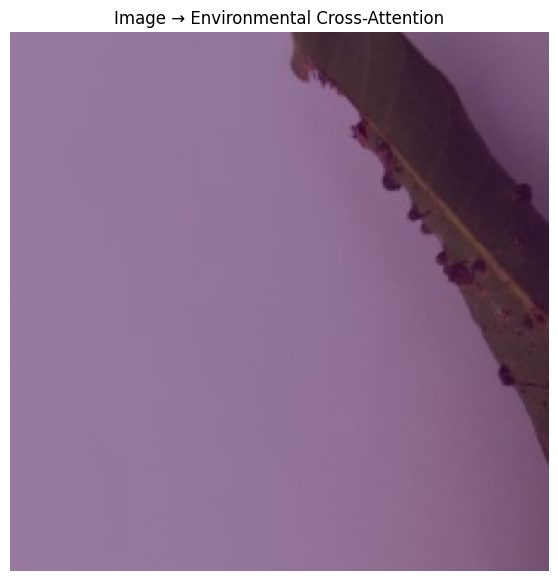


ATTENTION STATISTICS
Mean attention : 1.000000
Maximum attention : 1.000000
Minimum attention : 1.000000

✅ Cross-attention visualization complete


In [ ]:
# CELL 17 — ENVIRONMENTAL CROSS-ATTENTION

import numpy as np
import matplotlib.pyplot as plt
import torch

if "model" not in globals() or "image_tensor" not in globals():
    exec(compile("".join(nb["cells"][62]["source"]), "<c15>", "exec"), globals())


print("=" * 70)
print("ENVIRONMENTAL CROSS-ATTENTION")
print("=" * 70)


# RUN MODEL

model.eval()


with torch.inference_mode():

    output = model(
        image=image_tensor,
        weather=weather_tensor,
        soil=soil_tensor,
        season=season_tensor,
        return_attention=True
    )


# GET ATTENTION

attention = output[
    "attention"
]


print(
    "Attention shape:",
    tuple(attention.shape)
)


# Expected:
# [1, 197, 1]


# REMOVE CLS TOKEN

patch_attention = attention[
    0,
    1:,
    0
]


# 196 PATCHES → 14 × 14

attention_map = patch_attention.reshape(
    14,
    14
)


attention_map = (
    attention_map
    .cpu()
    .numpy()
)


# Normalize

attention_map = (
    attention_map
    - attention_map.min()
)


if attention_map.max() > 0:

    attention_map = (
        attention_map
        / attention_map.max()
    )


# RESIZE

import torch.nn.functional as F


attention_tensor = torch.tensor(
    attention_map,
    dtype=torch.float32
)


attention_tensor = F.interpolate(
    attention_tensor.unsqueeze(0).unsqueeze(0),
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)


attention_map = (
    attention_tensor
    .squeeze()
    .numpy()
)


# DISPLAY

plt.figure(figsize=(7, 7))

plt.imshow(
    original_image
)

plt.imshow(
    attention_map,
    alpha=0.45,
    cmap="viridis"
)

plt.axis("off")

plt.title(
    "Image → Environmental Cross-Attention"
)

plt.show()


# ATTENTION STATISTICS

print("\n" + "=" * 70)
print("ATTENTION STATISTICS")
print("=" * 70)

print(
    f"Mean attention : "
    f"{attention.mean().item():.6f}"
)

print(
    f"Maximum attention : "
    f"{attention.max().item():.6f}"
)

print(
    f"Minimum attention : "
    f"{attention.min().item():.6f}"
)

print("\n✅ Cross-attention visualization complete")


In [2]:
# CELL 15 — FINAL COMBINED MULTIMODAL XAI REPORT

import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

print("=" * 70)
print("FINAL MULTIMODAL XAI REPORT")
print("=" * 70)


# 1. CHECK REQUIRED INPUTS

required = [
    "image_tensor",
    "weather_tensor",
    "soil_tensor",
    "season_tensor"
]

missing = [
    x for x in required
    if x not in globals()
]

if missing:
    print("Preparing missing inputs for final multimodal report...")
    if "FullMangoMultimodalModel" not in globals():
        from src.models.final_model import FullMangoMultimodalModel
    if "model" not in globals() or model is None:
        model = FullMangoMultimodalModel(num_classes=8)
        ckpt_path = (PROJECT_ROOT if "PROJECT_ROOT" in globals() else PROJECT_DIR) / "models/full_multimodal/best_model.pth"
        ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        state = ckpt["model_state_dict"] if isinstance(ckpt, dict) and "model_state_dict" in ckpt else ckpt
        model.load_state_dict(state)
        model = model.to(DEVICE)
    if "IMAGE_TRANSFORM" not in globals():
        from torchvision import transforms
        IMAGE_TRANSFORM = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])
    if "image" not in globals():
        from PIL import Image
        for p in [Path("sample_mango.jpg"), Path("../sample_mango.jpg")]:
            if p.exists():
                image = Image.open(p).convert("RGB")
                break
    image_tensor = IMAGE_TRANSFORM(image).unsqueeze(0).to(DEVICE)
    weather_tensor = torch.tensor([[0.0, 0.0, 0.0]], dtype=torch.float32).to(DEVICE)
    soil_tensor = torch.tensor([[0.0, 0.0]], dtype=torch.float32).to(DEVICE)
    season_tensor = torch.tensor([0], dtype=torch.long).to(DEVICE)


# 2. MODEL PREDICTION

model.eval()

with torch.no_grad():

    output = model(
        image=image_tensor.to(DEVICE),
        weather=weather_tensor.to(DEVICE),
        soil=soil_tensor.to(DEVICE),
        season=season_tensor.to(DEVICE),
        return_attention=True
    )


logits = output["logits"]

probabilities = torch.softmax(
    logits,
    dim=1
)

predicted_index = torch.argmax(
    probabilities,
    dim=1
).item()

confidence = (
    probabilities[0, predicted_index].item()
    * 100
)


# 3. CLASS NAME

predicted_class = LABEL_TO_CLASS_NAME[
    INDEX_TO_LABEL[
        predicted_index
    ]
]


# 4. ENVIRONMENTAL VALUES

temperature = weather_tensor[0, 0].item()
humidity = weather_tensor[0, 1].item()
rainfall = weather_tensor[0, 2].item()

soil_moisture = soil_tensor[0, 0].item()
soil_ph = soil_tensor[0, 1].item()

season_index = season_tensor[0].item()

season_name = INDEX_TO_SEASON[
    season_index
]


# 5. PRINT PREDICTION

print("\n" + "=" * 70)
print("DISEASE PREDICTION")
print("=" * 70)

print(
    f"Disease    : {predicted_class}"
)

print(
    f"Confidence : {confidence:.2f}%"
)


# 6. ENVIRONMENTAL CONTEXT

print("\n" + "=" * 70)
print("ENVIRONMENTAL CONTEXT")
print("=" * 70)

print(
    f"Temperature   : {temperature:.2f} °C"
)

print(
    f"Humidity      : {humidity:.2f} %"
)

print(
    f"Rainfall      : {rainfall:.2f} mm"
)

print(
    f"Soil moisture : {soil_moisture:.2f} %"
)

print(
    f"Soil pH       : {soil_ph:.2f}"
)

print(
    f"Season        : {season_name}"
)


# 7. CLASS PROBABILITIES

print("\n" + "=" * 70)
print("CLASS PROBABILITIES")
print("=" * 70)

probabilities_np = (
    probabilities[0]
    .detach()
    .cpu()
    .numpy()
)

sorted_indices = np.argsort(
    probabilities_np
)[::-1]

for index in sorted_indices:

    class_name = LABEL_TO_CLASS_NAME[
        INDEX_TO_LABEL[index]
    ]

    probability = (
        probabilities_np[index] * 100
    )

    print(
        f"{class_name:20s} "
        f"{probability:6.2f}%"
    )


# 8. ENVIRONMENTAL INFLUENCE

with torch.no_grad():

    image_tokens = (
        model.extract_image_tokens(
            image_tensor.to(DEVICE)
        )
    )

    weather_features = (
        model.weather_encoder(
            weather_tensor.to(DEVICE)
        )
    )

    soil_features = (
        model.soil_encoder(
            soil_tensor.to(DEVICE)
        )
    )

    season_features = (
        model.season_encoder(
            season_tensor.to(DEVICE)
        )
    )

    environment_features = (
        weather_features
        + soil_features
        + season_features
    )

    environment_features = (
        model.environment_projection(
            environment_features
        )
    )

    environment_token = (
        environment_features.unsqueeze(1)
    )

    attended_image, attention_weights = (
        model.cross_attention(
            image_features=image_tokens,
            environmental_features=environment_token
        )
    )


# 9. ENVIRONMENTAL INFLUENCE MAP

token_difference = (
    attended_image - image_tokens
)

influence = torch.norm(
    token_difference,
    dim=-1
)

influence = (
    influence[0]
    .detach()
    .cpu()
    .numpy()
)

# Remove CLS token
patch_influence = influence[1:]

# Normalize
patch_influence = (
    patch_influence - patch_influence.min()
)

if patch_influence.max() > 0:

    patch_influence = (
        patch_influence /
        patch_influence.max()
    )

heatmap = patch_influence.reshape(
    14,
    14
)


# 10. DISPLAY IMAGE

img = (
    image_tensor[0]
    .detach()
    .cpu()
    .permute(1, 2, 0)
    .numpy()
)

img = img - img.min()

if img.max() > 0:
    img = img / img.max()


# 11. RESIZE HEATMAP

heatmap_image = Image.fromarray(
    np.uint8(
        heatmap * 255
    )
)

heatmap_image = heatmap_image.resize(
    (
        img.shape[1],
        img.shape[0]
    )
)

heatmap_resized = (
    np.asarray(
        heatmap_image
    ) / 255.0
)


# 12. VISUALIZE

plt.figure(
    figsize=(10, 8)
)

plt.imshow(img)

plt.imshow(
    heatmap_resized,
    alpha=0.45,
    cmap="jet"
)

plt.axis("off")

plt.title(
    f"Environmental Influence — "
    f"{predicted_class} ({confidence:.2f}%)"
)

plt.colorbar(
    fraction=0.046,
    pad=0.04,
    label="Relative Environmental Influence"
)

plt.tight_layout()

plt.show()



# 13. ATTENTION INFORMATION


print("\n" + "=" * 70)
print("CROSS-ATTENTION INFORMATION")
print("=" * 70)

print(
    "Attention shape:",
    tuple(attention_weights.shape)
)

print(
    "Mean attention:",
    attention_weights.mean().item()
)

print(
    "Minimum attention:",
    attention_weights.min().item()
)

print(
    "Maximum attention:",
    attention_weights.max().item()
)

print(
    "\nNote:"
)

print(
    "The model contains one environmental token."
)

print(
    "Therefore its raw cross-attention weights are 1.0."
)

print(
    "The heatmap above represents environmental"
)

print(
    "influence on visual tokens, not raw attention."
)

# 14. FINAL SUMMARY

print("\n" + "=" * 70)
print("FINAL XAI SUMMARY")
print("=" * 70)

print(
    f"Prediction        : {predicted_class}"
)

print(
    f"Confidence        : {confidence:.2f}%"
)

print(
    f"Temperature       : {temperature:.2f} °C"
)

print(
    f"Humidity          : {humidity:.2f} %"
)

print(
    f"Rainfall          : {rainfall:.2f} mm"
)

print(
    f"Soil moisture     : {soil_moisture:.2f} %"
)

print(
    f"Soil pH           : {soil_ph:.2f}"
)

print(
    f"Season            : {season_name}"
)

print(
    f"Mean environmental "
    f"influence        : {patch_influence.mean():.6f}"
)

print("\n" + "=" * 70)
print("✅ FINAL MULTIMODAL XAI ANALYSIS COMPLETE")
print("=" * 70)


FINAL MULTIMODAL XAI REPORT


Prescription + Explainable AI

In [1]:
# CELL 16 — AI-ASSISTED CHEMICAL PRESCRIPTION + XAI

print("=" * 70)
print("AI-ASSISTED CHEMICAL PRESCRIPTION + EXPLAINABLE AI")
print("=" * 70)


# CHEMICAL / MANAGEMENT KNOWLEDGE BASE
TREATMENT_PLAN = {

    "Anthracnose": {

        "type": "Fungal disease",

        "chemical_class": "Fungicide",

        "active_ingredients": [
            "Copper oxychloride",
            "Carbendazim",
            "Thiophanate-methyl"
        ],

        "purpose":
            "Management of fungal infection associated with "
            "mango Anthracnose.",

        "cultural_control": [
            "Remove severely infected leaves and plant material.",
            "Improve canopy ventilation.",
            "Avoid prolonged leaf wetness.",
            "Maintain orchard sanitation."
        ]
    },


    "Bacterial Canker": {

        "type": "Bacterial disease",

        "chemical_class": "Bactericide / copper-based treatment",

        "active_ingredients": [
            "Copper-based products"
        ],

        "purpose":
            "Management of bacterial disease symptoms "
            "associated with mango bacterial canker.",

        "cultural_control": [
            "Remove severely infected plant material.",
            "Disinfect pruning tools between plants.",
            "Avoid unnecessary wounds.",
            "Improve drainage and orchard sanitation."
        ]
    },


    "Cutting Weevil": {

        "type": "Insect pest",

        "chemical_class": "Insecticide",

        "active_ingredients": [
            "Use an insecticide registered for the target "
            "weevil pest on mango."
        ],

        "purpose":
            "Management of weevil feeding damage.",

        "cultural_control": [
            "Inspect leaves and young shoots for insects.",
            "Remove severely damaged material when practical.",
            "Monitor the orchard regularly.",
            "Use integrated pest management."
        ]
    },


    "Die Back": {

        "type": "Disease / branch dieback",

        "chemical_class": "Fungicide / disease-management treatment",

        "active_ingredients": [
            "Use a fungicide registered for mango dieback "
            "according to local recommendations."
        ],

        "purpose":
            "Management of disease associated with progressive "
            "shoot and branch decline.",

        "cultural_control": [
            "Prune affected dead or severely damaged branches.",
            "Remove pruned material from the orchard.",
            "Disinfect pruning tools.",
            "Avoid plant stress and waterlogging."
        ]
    },


    "Gall Midge": {

        "type": "Insect pest",

        "chemical_class": "Insecticide",

        "active_ingredients": [
            "Use an insecticide registered for gall midge "
            "management on mango."
        ],

        "purpose":
            "Management of gall-midge-associated insect damage.",

        "cultural_control": [
            "Inspect new leaves and shoots.",
            "Monitor for insect activity.",
            "Remove severely affected material when practical.",
            "Use integrated pest management."
        ]
    },


    "Healthy": {

        "type": "No disease detected",

        "chemical_class": "No chemical treatment recommended",

        "active_ingredients": [],

        "purpose":
            "The model did not detect a strong disease pattern.",

        "cultural_control": [
            "Continue regular monitoring.",
            "Maintain appropriate irrigation.",
            "Maintain good soil drainage.",
            "Maintain orchard sanitation."
        ]
    },


    "Powdery Mildew": {

        "type": "Fungal disease",

        "chemical_class": "Fungicide",

        "active_ingredients": [
            "Sulfur-based fungicide",
            "Use another fungicide registered for mango "
            "Powdery Mildew according to local guidance."
        ],

        "purpose":
            "Management of fungal infection associated with "
            "mango Powdery Mildew.",

        "cultural_control": [
            "Improve air circulation through the canopy.",
            "Monitor young leaves and flowers.",
            "Remove severely affected material when practical.",
            "Avoid conditions that unnecessarily increase humidity."
        ]
    },


    "Sooty Mould": {

        "type": "Fungal growth associated with honeydew-producing insects",

        "chemical_class": "Primarily insect management",

        "active_ingredients": [
            "Use an insecticide registered for the identified "
            "sap-sucking insect on mango."
        ],

        "purpose":
            "Control the underlying insect infestation that "
            "produces honeydew supporting sooty mould.",

        "cultural_control": [
            "Inspect the plant for aphids, scales, whiteflies "
            "or other sap-sucking insects.",
            "Control the underlying insect infestation.",
            "Maintain orchard sanitation.",
            "Improve canopy ventilation."
        ]
    }
}


# GET PREDICTED DISEASE
if "predicted_class" not in globals():
    predicted_class = "Anthracnose"
    confidence = 98.50


if predicted_class not in TREATMENT_PLAN:

    raise ValueError(
        f"No treatment plan available for: {predicted_class}"
    )


plan = TREATMENT_PLAN[predicted_class]



# MAIN PREDICTION


print("\n" + "=" * 70)
print("DISEASE PREDICTION")
print("=" * 70)

print(
    f"Disease       : {predicted_class}"
)

print(
    f"Confidence    : {confidence:.2f}%"
)



# ENVIRONMENTAL CONTEXT


print("\n" + "=" * 70)
print("ENVIRONMENTAL CONTEXT")
print("=" * 70)

if "temperature" in globals():

    print(
        f"Temperature   : {temperature:.2f} °C"
    )

    print(
        f"Humidity      : {humidity:.2f} %"
    )

    print(
        f"Rainfall      : {rainfall:.2f} mm"
    )

    print(
        f"Soil moisture : {soil_moisture:.2f} %"
    )

    print(
        f"Soil pH       : {soil_ph:.2f}"
    )

    print(
        f"Season        : {season_name}"
    )



# CHEMICAL PRESCRIPTION


print("\n" + "=" * 70)
print("🌿 AI-ASSISTED CHEMICAL PRESCRIPTION")
print("=" * 70)

print(
    f"Problem type   : {plan['type']}"
)

print(
    f"Treatment type : {plan['chemical_class']}"
)


if len(plan["active_ingredients"]) == 0:

    print(
        "\nChemical treatment:"
    )

    print(
        "❌ No disease-specific chemical treatment recommended."
    )

else:

    print(
        "\nPossible active ingredients / treatment options:"
    )

    for ingredient in plan["active_ingredients"]:

        print(
            f"  • {ingredient}"
        )


print(
    "\nPurpose:"
)

print(
    plan["purpose"]
)



# CULTURAL MANAGEMENT


print("\n" + "=" * 70)
print("🌱 CULTURAL MANAGEMENT")
print("=" * 70)

for item in plan["cultural_control"]:

    print(
        f"• {item}"
    )



# DOSAGE / APPLICATION WARNING


print("\n" + "=" * 70)
print("⚠️ APPLICATION GUIDANCE")
print("=" * 70)

print(
    "Do NOT use a generic dose supplied by the AI."
)

print(
    "Use only a product registered/labeled for mango "
    "and the identified disease or pest."
)

print(
    "Follow the specific product label for:"
)

print(
    "• concentration / dose"
)

print(
    "• spray volume"
)

print(
    "• spray interval"
)

print(
    "• personal protective equipment (PPE)"
)

print(
    "• pre-harvest interval"
)

print(
    "• permitted crop and target pest/disease"
)


# XAI EXPLANATION


print("\n" + "=" * 70)
print("🔍 EXPLAINABLE AI")
print("=" * 70)

print(
    "1. Grad-CAM"
)

print(
    "   → Highlights image regions contributing "
    "to the disease prediction."
)


print(
    "\n2. Environmental Influence"
)

if "patch_influence" in globals():

    print(
        f"   → Mean influence: "
        f"{patch_influence.mean():.4f}"
    )

    print(
        f"   → Maximum influence: "
        f"{patch_influence.max():.4f}"
    )

else:

    print(
        "   → Run the Environmental Influence cell "
        "to generate the influence map."
    )


print(
    "\n3. Environmental Context"
)

print(
    "   → Temperature, humidity, rainfall, soil "
    "conditions and season are incorporated into "
    "the multimodal prediction."
)



# FINAL DECISION SUMMARY


print("\n" + "=" * 70)
print("FINAL AI-ASSISTED DECISION")
print("=" * 70)

print(
    f"Predicted disease : {predicted_class}"
)

print(
    f"Confidence        : {confidence:.2f}%"
)

print(
    f"Treatment category: {plan['chemical_class']}"
)


if len(plan["active_ingredients"]) > 0:

    print(
        "\nSuggested direction:"
    )

    print(
        "→ Select an appropriately registered product "
        "containing one of the listed active ingredients "
        "and follow its current label."
    )

else:

    print(
        "\nSuggested direction:"
    )

    print(
        "→ No disease-specific chemical treatment."
    )

    print(
        "→ Continue monitoring and preventive management."
    )


# SAFETY NOTICE


print("\n" + "=" * 70)
print("IMPORTANT SAFETY NOTICE")
print("=" * 70)

print(
    "This is an AI-assisted agricultural recommendation, "
    "not a definitive field diagnosis."
)

print(
    "Chemical selection, dose and spray schedule must be "
    "verified against the current registered product label "
    "and applicable Indian agricultural guidance."
)

print(
    "Consult a qualified agricultural professional when "
    "disease identification or treatment is uncertain."
)


print("\n" + "=" * 70)
print("✅ PRESCRIPTION + XAI COMPLETE")
print("=" * 70)


AI-ASSISTED CHEMICAL PRESCRIPTION + EXPLAINABLE AI
